In [1]:
import pyVIA.core as via
import pyVIA.datasets_via as   datasets
import pandas as pd 
import scanpy as sc

import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

/data/ep924610/miniforge3/envs/ViaEnv/lib/python3.10/site-packages/phate/__init__.py


In [2]:
adata = sc.read_h5ad("/data/ep924610/kidney_biopsy/trajectory_pec/pec_annotated.h5ad")

In [3]:
adata = adata[:, ~adata.var_names.str.startswith('MALAT1')].copy()

In [4]:
adata.obs["pec_subcluster_0.80"].unique()

['0_PEC/aPT1', '5_SPP1⁺ aPT/aPEC', '7_aPEC', '9_Pod/PEC', '1_PEC/aPT2', ..., '6_WT1+ PEC', '4_PEC/aPT3', '3_Pod/PEC', '8_aPEC/inflPEC', '10_Pod']
Length: 11
Categories (11, object): ['0_PEC/aPT1' < '1_PEC/aPT2' < '2_aPECs' < '3_Pod/PEC' ... '7_aPEC' < '8_aPEC/inflPEC' < '9_Pod/PEC' < '10_Pod']

In [6]:
adata = adata[adata.obs["leiden_res_0.80"] != "10"].copy()
adata = adata[adata.obs["pec_subcluster_0.80"] != "9_Pod/PEC"].copy()
adata = adata[adata.obs["pec_subcluster_0.80"] != "6_WT1+ PEC"].copy()

In [7]:
adata.obs["pec_subcluster_0.80"].unique()

['0_PEC/aPT1', '5_SPP1⁺ aPT/aPEC', '7_aPEC', '1_PEC/aPT2', '2_aPECs', '4_PEC/aPT3', '3_Pod/PEC', '8_aPEC/inflPEC']
Categories (8, object): ['0_PEC/aPT1' < '1_PEC/aPT2' < '2_aPECs' < '3_Pod/PEC' < '4_PEC/aPT3' < '5_SPP1⁺ aPT/aPEC' < '7_aPEC' < '8_aPEC/inflPEC']

In [8]:
sc.tl.diffmap(adata)

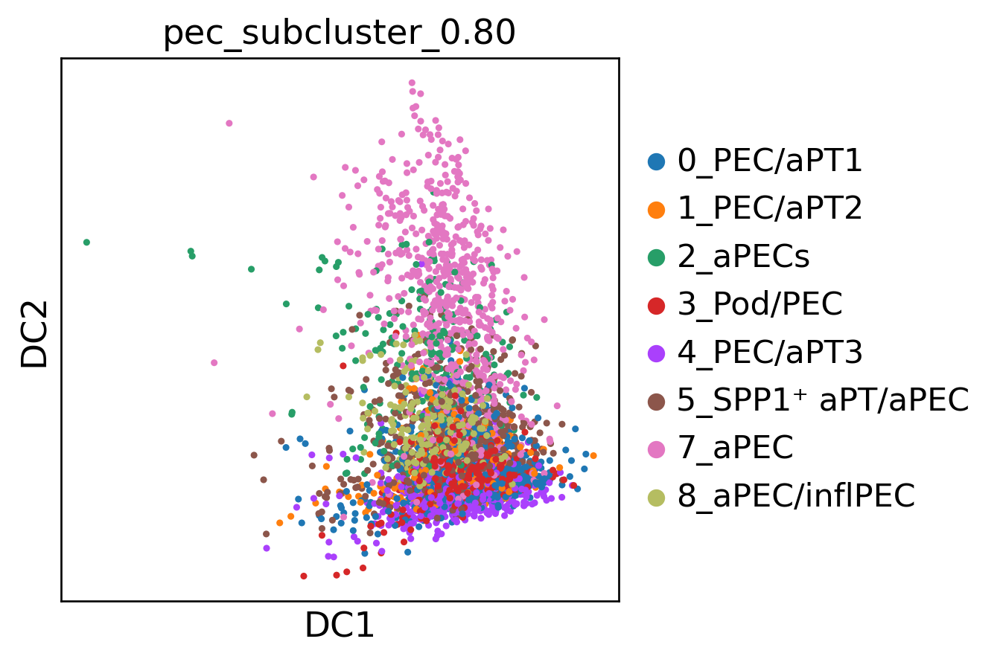

In [9]:
sc.pl.diffmap(adata, color = "pec_subcluster_0.80")

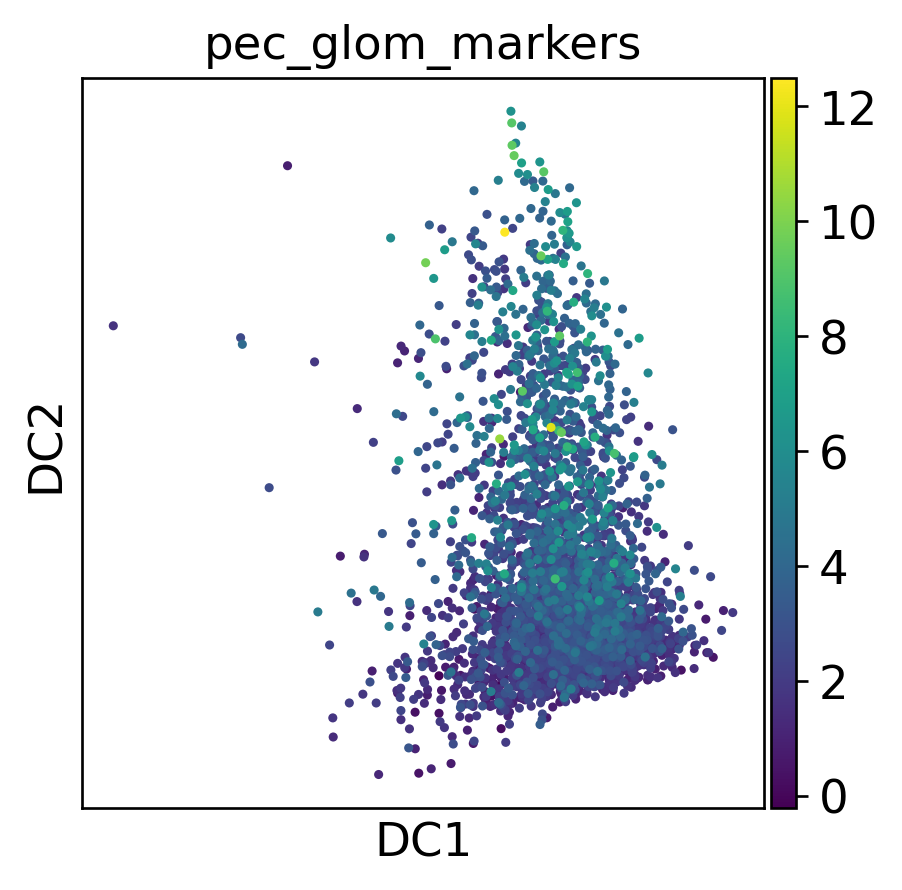

In [10]:
sc.pl.diffmap(adata, color = "pec_glom_markers")

In [11]:
sc.external.tl.phate(adata, random_state= 4)

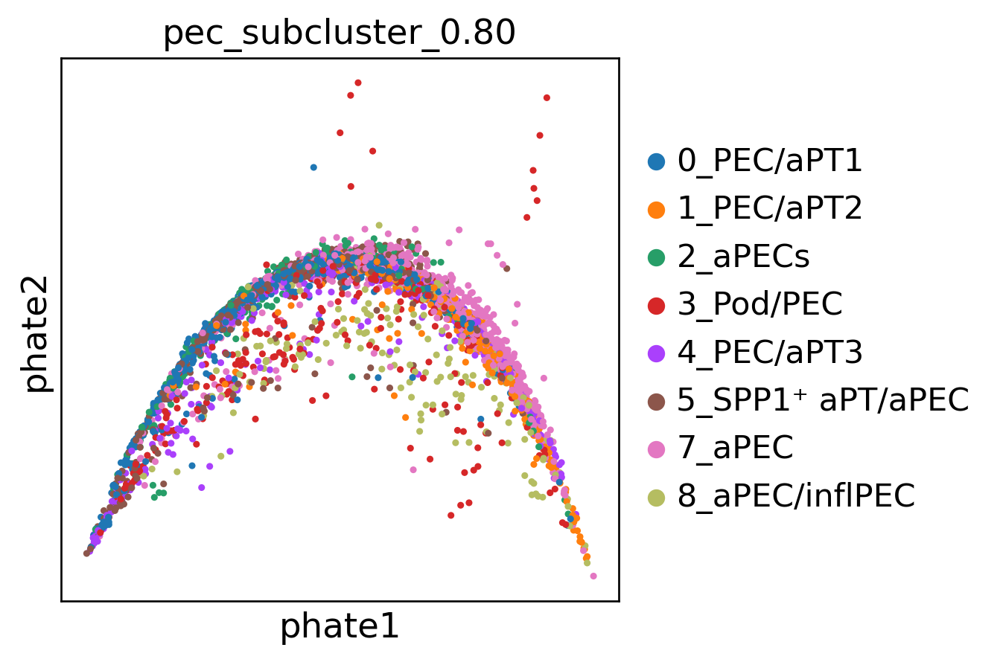

In [12]:
sc.external.pl.phate(adata, color = ["pec_subcluster_0.80"])

In [13]:
adata

AnnData object with n_obs × n_vars = 4032 × 21840
    obs: 'donor_id', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'Sample', 'Group', 'date_of_biopsy_h5ad', 'ACEi', 'AT2i', 'Statin', 'corticosteroids_h5ad', 'region', 'RNAversion', 'nCounts_RNA', 'nFeatures_RNA', 'percMT_RNA', 'is_cell', 'QC1', 'pANN', 'DF', 'sclust_A', 'sclust_B', 'sclust_C', 'sclust_D', 'sclust_E', 'clust_A', 'clust_B', 'clust_C', 'clust_D', 'clust_E', 'predicted.annotation.l3.score', 'predicted.annotation.l3', 'predicted.annotation.l3.MappingScore', 'predicted.annotation.l1', 'predicted.annotation.l2', 'unfiltered_Doublets', 'leiden01', 'leiden03', 'leiden02', 'leiden04', 'subcluster_01_do_not_use', 'subcluster_02_do_not_use', 'subcluster_03_do_not_use', 'Main_Cluster_do_not_use', 'Cell_types_KPMP_do_not_use', 'Cell_types_Subclustering_do_not_use', 'Cell_types_Subclustering2_do_not_use', 'barcode_sample', 'main_class', 'subcluster', 'Study', 'library_id', 'percent.er', 'percent.mt', 'subclass.l2', 'su

In [14]:
adata.obs["pec_subcluster_0.80"].unique()

['0_PEC/aPT1', '5_SPP1⁺ aPT/aPEC', '7_aPEC', '1_PEC/aPT2', '2_aPECs', '4_PEC/aPT3', '3_Pod/PEC', '8_aPEC/inflPEC']
Categories (8, object): ['0_PEC/aPT1' < '1_PEC/aPT2' < '2_aPECs' < '3_Pod/PEC' < '4_PEC/aPT3' < '5_SPP1⁺ aPT/aPEC' < '7_aPEC' < '8_aPEC/inflPEC']

In [15]:
knn=15
v0_random_seed=4
root_user = ["4_PEC/aPT3"] #the index of a cell belonging to the HSC cell type
memory = 5
dataset = 'group'

'''
#NOTE1, if you decide to choose a cell type as a root, then you need to set the dataset as 'group'
#root_user=['HSC1']
#dataset = 'group'# 'humanCD34'
#NOTE2, if rna-velocity is available, considering using it to compute the root automatically- see RNA velocity tutorial
'''

v0 = via.VIA(data=adata.obsm["X_diffmap"], true_label=adata.obs['pec_subcluster_0.80'], 
             edgepruning_clustering_resolution=0.15, cluster_graph_pruning=0.5,
             knn=knn,  root_user=root_user, resolution_parameter=1.5,
             dataset=dataset, random_seed=v0_random_seed, memory=memory, do_compute_embedding=False, user_defined_terminal_group = ["7_aPEC"])#, embedding_type='via_umap')

v0.run_VIA()

#NOTE2: if you want to pre-specify terminal states you can do so by a list of group-level names corresponding to true-labels OR by a list of single cell indices
#E.G. user_defined_terminal_group=['pDC','ERY1', 'ERY3', 'MONO1','mDC (cDC)','PRE_B2']

2025-10-31 13:54:36.925856	Running VIA over input data of 4032 (samples) x 15 (features)
2025-10-31 13:54:36.926152	Knngraph has 15 neighbors
2025-10-31 13:54:39.750707	Finished global pruning of 15-knn graph used for clustering at level of 0.15. Kept 47.9 % of edges. 
2025-10-31 13:54:39.794134	Number of connected components used for clustergraph  is 1
2025-10-31 13:54:39.962242	Commencing community detection
2025-10-31 13:54:40.420639	Finished community detection. Found 220 clusters.
2025-10-31 13:54:40.423242	Merging 150 very small clusters (<10)
2025-10-31 13:54:40.425272	Finished detecting communities. Found 70 communities
2025-10-31 13:54:40.425643	Making cluster graph. Global cluster graph pruning level: 0.5
2025-10-31 13:54:40.433410	Graph has 1 connected components before pruning
2025-10-31 13:54:40.449947	Graph has 1 connected components after pruning
2025-10-31 13:54:40.450170	Graph has 1 connected components after reconnecting
2025-10-31 13:54:40.450827	0.4% links trimmed f

  0%|                                                                                          | 0/1300 [00:00…

memory for rw2 hittings times  2. Using rw2 based pt
2025-10-31 13:54:53.124892	Terminal cluster list based on user defined cells/groups: [('7_aPEC', 12)]
2025-10-31 13:54:53.124945	Terminal clusters corresponding to unique lineages in this component are [12] 
2025-10-31 13:54:53.124959	Calculating lineage probability at memory 5


  0%|                                                                                          | 0/1000 [00:00…

2025-10-31 13:55:00.621592	Cluster or terminal cell fate 12 is reached 97.0 times
2025-10-31 13:55:00.639950	There are (1) terminal clusters corresponding to unique lineages {12: '7_aPEC'}
2025-10-31 13:55:00.639976	Begin projection of pseudotime and lineage likelihood
2025-10-31 13:55:01.865906	Cluster graph layout based on forward biasing
2025-10-31 13:55:01.883744	Starting make edgebundle viagraph...
2025-10-31 13:55:01.883776	Make via clustergraph edgebundle
2025-10-31 13:55:06.136623	Hammer dims: Nodes shape: (70, 2) Edges shape: (592, 3)
2025-10-31 13:55:06.138384	Graph has 1 connected components before pruning
2025-10-31 13:55:06.141203	Graph has 22 connected components after pruning
2025-10-31 13:55:06.169096	Graph has 1 connected components after reconnecting
2025-10-31 13:55:06.169807	76.5% links trimmed from local pruning relative to start
2025-10-31 13:55:06.169838	81.9% links trimmed from global pruning relative to start
initial links 592 and final_links_n 139
2025-10-31 1

adata.X: <class 'scipy.sparse._csr.csr_matrix'>
adata.X shape: (4032, 21840)
n_cells: 4032 n_vars: 21840
len(var_names): 21840
Has raw: False
Layers: []
Using expression from: X with shape (4032, 21840)
Markers present: ['CD44', 'TMSB10', 'SPECC1', 'ITGB1', 'MMP7', 'PDLIM7', 'EPHB2', 'ITGA11', 'RUNX1', 'SOX4']
Markers missing: []
shape of transition matrix raised to power 3 (4032, 4032)
Area under curve CD44 for branch 7_aPEC is 0.06901385242666419
Area under curve TMSB10 for branch 7_aPEC is 0.19656976817592658
Area under curve SPECC1 for branch 7_aPEC is 0.19783164088788413
Area under curve ITGB1 for branch 7_aPEC is 0.45827265350402024
Area under curve MMP7 for branch 7_aPEC is 0.16185803639466093
Area under curve PDLIM7 for branch 7_aPEC is 0.23438529454534418
Area under curve EPHB2 for branch 7_aPEC is 0.5856964353005065
Area under curve ITGA11 for branch 7_aPEC is 0.6911315017015315
Area under curve RUNX1 for branch 7_aPEC is 0.662492642278733
Area under curve SOX4 for branch 7_a

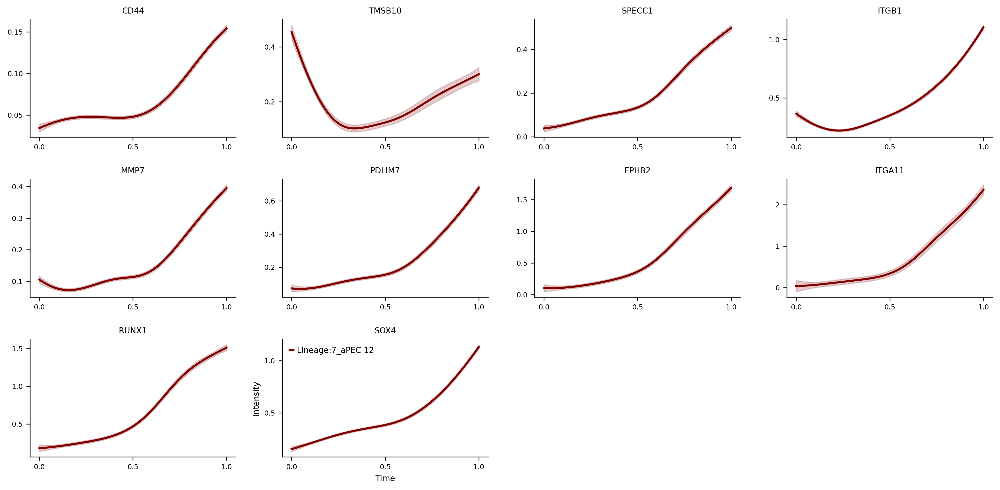

In [16]:
import numpy as np
import pandas as pd
import scanpy as sc

# 1) Basic inspection
print("adata.X:", type(adata.X))
try:
    print("adata.X shape:", adata.X.shape)
except Exception as e:
    print("adata.X shape error:", e)

print("n_cells:", adata.n_obs, "n_vars:", adata.n_vars)
print("len(var_names):", len(adata.var_names))
print("Has raw:", adata.raw is not None)
if adata.raw is not None:
    print("raw.X type:", type(adata.raw.X))
    try:
        print("raw.X shape:", adata.raw.X.shape)
    except Exception as e:
        print("raw.X shape error:", e)

print("Layers:", list(adata.layers.keys()) if adata.layers is not None else "no layers")

# 2) Pick an expression matrix to use (prefer raw if present and matches genes)
def to_dense(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    if hasattr(X, "A"):
        return X.A
    return np.asarray(X)

X = None
genes = None
source = None

# Prefer raw if it exists and has more than 1 gene
if adata.raw is not None:
    X_raw = to_dense(adata.raw.X)
    if X_raw.ndim == 2 and X_raw.shape[1] > 1:
        X = X_raw
        genes = adata.raw.var_names
        source = "raw"
    else:
        print("Warning: adata.raw.X not usable (shape:", X_raw.shape, ")")

# If not chosen, try adata.X
if X is None:
    X_x = to_dense(adata.X)
    if X_x.ndim == 2 and X_x.shape[1] == len(adata.var_names) and X_x.shape[1] > 1:
        X = X_x
        genes = adata.var_names
        source = "X"
    else:
        print("Warning: adata.X not usable (shape:", getattr(adata.X, "shape", None), ")")

# If still none, search layers for a likely expression matrix
if X is None and adata.layers is not None and len(adata.layers) > 0:
    candidate_keys = ["counts", "raw", "log1p", "lognorm", "normalized", "norm", "scaled"]
    keys_in_layers = list(adata.layers.keys())
    # try preferred keys first, then any layer that looks like (n_cells, n_genes)
    for key in candidate_keys + keys_in_layers:
        if key in adata.layers:
            X_layer = to_dense(adata.layers[key])
            if X_layer.ndim == 2 and X_layer.shape[0] == adata.n_obs and X_layer.shape[1] == len(adata.var_names) and X_layer.shape[1] > 1:
                X = X_layer
                genes = adata.var_names
                source = f"layers['{key}']"
                break

if X is None:
    raise RuntimeError("Could not find a valid expression matrix in adata.raw, adata.X, or adata.layers.")

print(f"Using expression from: {source} with shape {X.shape}")

# 3) Build DataFrame
df = pd.DataFrame(X, index=adata.obs_names, columns=genes)

# 4) Restrict to available markers
marker_genes = [
    'CD44','TMSB10','SPECC1','ITGB1','MMP7','PDLIM7','EPHB2','ITGA11','RUNX1','SOX4'
]
markers_present = [g for g in marker_genes if g in df.columns]
markers_missing = [g for g in marker_genes if g not in df.columns]

print("Markers present:", markers_present)
print("Markers missing:", markers_missing)
if len(markers_present) == 0:
    raise ValueError("None of the requested marker genes are present in the expression matrix.")

# Optional: subset df to just the markers for speed (VIA will also handle gene_list)
df_subset = df[markers_present]

# 5) Run VIA imputation and plotting
df_magic = v0.do_impute(df_subset, magic_steps=3, gene_list=markers_present)
fig, axs = via.get_gene_expression(via_object=v0, gene_exp=df_magic)
fig.set_size_inches(14, 7)
fig.tight_layout()

adata.X: <class 'scipy.sparse._csr.csr_matrix'>
adata.X shape: (4032, 21840)
n_cells: 4032 n_vars: 21840
len(var_names): 21840
Has raw: False
Layers: []
Using expression from: X with shape (4032, 21840)
Markers present: ['SLC4A11', 'CDH1', 'FGFR2', 'PAH', 'PIGR']
Markers missing: []
shape of transition matrix raised to power 3 (4032, 4032)
Area under curve SLC4A11 for branch 7_aPEC is 0.6353203076947678
Area under curve CDH1 for branch 7_aPEC is 0.503536539130114
Area under curve FGFR2 for branch 7_aPEC is 0.5344870047014307
Area under curve PAH for branch 7_aPEC is 0.384401957835834
Area under curve PIGR for branch 7_aPEC is 0.1860060462491787


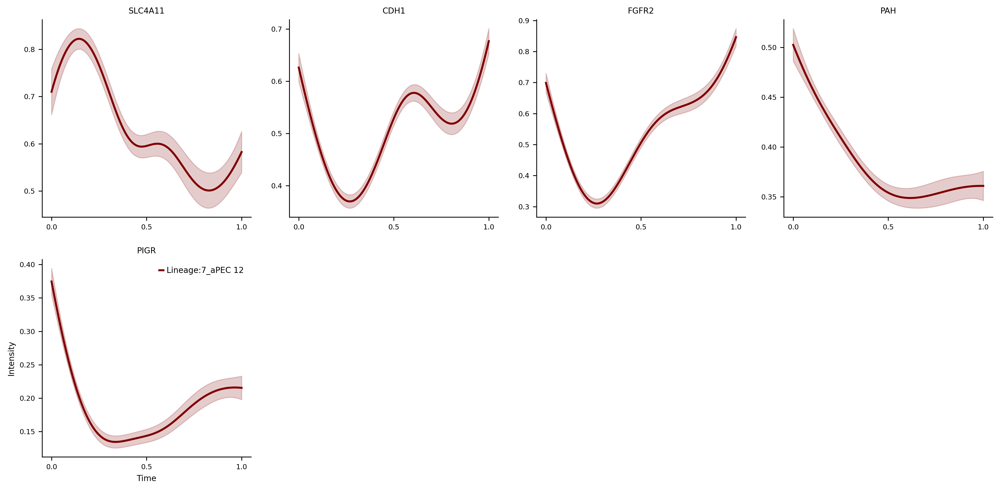

In [17]:
import numpy as np
import pandas as pd
import scanpy as sc

# 1) Basic inspection
print("adata.X:", type(adata.X))
try:
    print("adata.X shape:", adata.X.shape)
except Exception as e:
    print("adata.X shape error:", e)

print("n_cells:", adata.n_obs, "n_vars:", adata.n_vars)
print("len(var_names):", len(adata.var_names))
print("Has raw:", adata.raw is not None)
if adata.raw is not None:
    print("raw.X type:", type(adata.raw.X))
    try:
        print("raw.X shape:", adata.raw.X.shape)
    except Exception as e:
        print("raw.X shape error:", e)

print("Layers:", list(adata.layers.keys()) if adata.layers is not None else "no layers")

# 2) Pick an expression matrix to use (prefer raw if present and matches genes)
def to_dense(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    if hasattr(X, "A"):
        return X.A
    return np.asarray(X)

X = None
genes = None
source = None

# Prefer raw if it exists and has more than 1 gene
if adata.raw is not None:
    X_raw = to_dense(adata.raw.X)
    if X_raw.ndim == 2 and X_raw.shape[1] > 1:
        X = X_raw
        genes = adata.raw.var_names
        source = "raw"
    else:
        print("Warning: adata.raw.X not usable (shape:", X_raw.shape, ")")

# If not chosen, try adata.X
if X is None:
    X_x = to_dense(adata.X)
    if X_x.ndim == 2 and X_x.shape[1] == len(adata.var_names) and X_x.shape[1] > 1:
        X = X_x
        genes = adata.var_names
        source = "X"
    else:
        print("Warning: adata.X not usable (shape:", getattr(adata.X, "shape", None), ")")

# If still none, search layers for a likely expression matrix
if X is None and adata.layers is not None and len(adata.layers) > 0:
    candidate_keys = ["counts", "raw", "log1p", "lognorm", "normalized", "norm", "scaled"]
    keys_in_layers = list(adata.layers.keys())
    # try preferred keys first, then any layer that looks like (n_cells, n_genes)
    for key in candidate_keys + keys_in_layers:
        if key in adata.layers:
            X_layer = to_dense(adata.layers[key])
            if X_layer.ndim == 2 and X_layer.shape[0] == adata.n_obs and X_layer.shape[1] == len(adata.var_names) and X_layer.shape[1] > 1:
                X = X_layer
                genes = adata.var_names
                source = f"layers['{key}']"
                break

if X is None:
    raise RuntimeError("Could not find a valid expression matrix in adata.raw, adata.X, or adata.layers.")

print(f"Using expression from: {source} with shape {X.shape}")

# 3) Build DataFrame
df = pd.DataFrame(X, index=adata.obs_names, columns=genes)

# 4) Restrict to available markers
marker_genes = ["SLC4A11", "CDH1", "FGFR2", "PAH", "PIGR"]
markers_present = [g for g in marker_genes if g in df.columns]
markers_missing = [g for g in marker_genes if g not in df.columns]

print("Markers present:", markers_present)
print("Markers missing:", markers_missing)
if len(markers_present) == 0:
    raise ValueError("None of the requested marker genes are present in the expression matrix.")

# Optional: subset df to just the markers for speed (VIA will also handle gene_list)
df_subset = df[markers_present]

# 5) Run VIA imputation and plotting
df_magic = v0.do_impute(df_subset, magic_steps=3, gene_list=markers_present)
fig, axs = via.get_gene_expression(via_object=v0, gene_exp=df_magic)
fig.set_size_inches(14, 7)
fig.tight_layout()


tune edges False


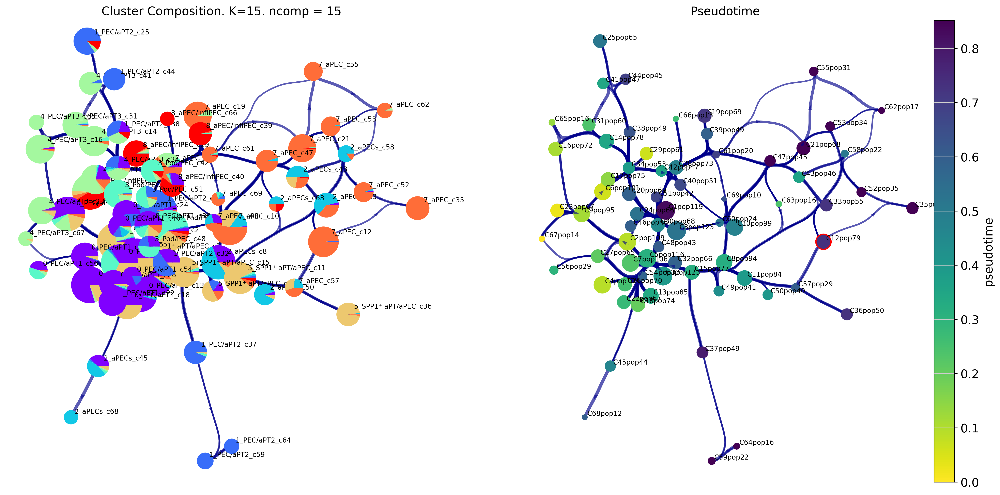

In [18]:
fig, ax, ax1 = via.plot_piechart_viagraph(via_object=v0, show_legend=False)
fig.set_size_inches(20,10)

adata.X: <class 'scipy.sparse._csr.csr_matrix'>
adata.X shape: (4032, 21840)
n_cells: 4032 n_vars: 21840
len(var_names): 21840
Has raw: False
Layers: []
Using expression from: X with shape (4032, 21840)
Markers present: ['CD44', 'TMSB10', 'SPECC1', 'ITGB1', 'MMP7', 'PDLIM7', 'EPHB2', 'ITGA11', 'RUNX1', 'SOX4']
Markers missing: []
shape of transition matrix raised to power 3 (4032, 4032)
Area under curve CD44 for branch 7_aPEC is 0.06901385242666419
Area under curve TMSB10 for branch 7_aPEC is 0.19656976817592658
Area under curve SPECC1 for branch 7_aPEC is 0.19783164088788413
Area under curve ITGB1 for branch 7_aPEC is 0.45827265350402024
Area under curve MMP7 for branch 7_aPEC is 0.16185803639466093
Area under curve PDLIM7 for branch 7_aPEC is 0.23438529454534418
Area under curve EPHB2 for branch 7_aPEC is 0.5856964353005065
Area under curve ITGA11 for branch 7_aPEC is 0.6911315017015315
Area under curve RUNX1 for branch 7_aPEC is 0.662492642278733
Area under curve SOX4 for branch 7_a

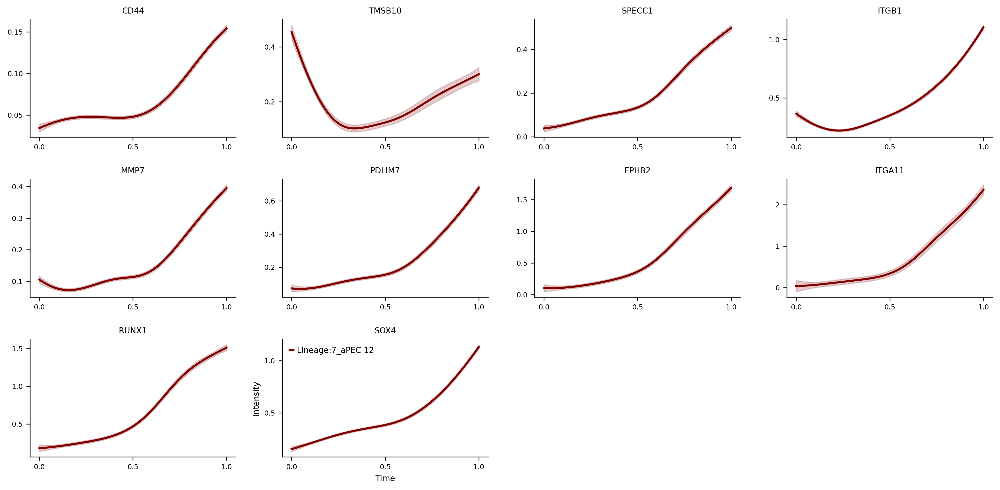

In [19]:
import numpy as np
import pandas as pd
import scanpy as sc

# 1) Basic inspection
print("adata.X:", type(adata.X))
try:
    print("adata.X shape:", adata.X.shape)
except Exception as e:
    print("adata.X shape error:", e)

print("n_cells:", adata.n_obs, "n_vars:", adata.n_vars)
print("len(var_names):", len(adata.var_names))
print("Has raw:", adata.raw is not None)
if adata.raw is not None:
    print("raw.X type:", type(adata.raw.X))
    try:
        print("raw.X shape:", adata.raw.X.shape)
    except Exception as e:
        print("raw.X shape error:", e)

print("Layers:", list(adata.layers.keys()) if adata.layers is not None else "no layers")

# 2) Pick an expression matrix to use (prefer raw if present and matches genes)
def to_dense(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    if hasattr(X, "A"):
        return X.A
    return np.asarray(X)

X = None
genes = None
source = None

# Prefer raw if it exists and has more than 1 gene
if adata.raw is not None:
    X_raw = to_dense(adata.raw.X)
    if X_raw.ndim == 2 and X_raw.shape[1] > 1:
        X = X_raw
        genes = adata.raw.var_names
        source = "raw"
    else:
        print("Warning: adata.raw.X not usable (shape:", X_raw.shape, ")")

# If not chosen, try adata.X
if X is None:
    X_x = to_dense(adata.X)
    if X_x.ndim == 2 and X_x.shape[1] == len(adata.var_names) and X_x.shape[1] > 1:
        X = X_x
        genes = adata.var_names
        source = "X"
    else:
        print("Warning: adata.X not usable (shape:", getattr(adata.X, "shape", None), ")")

# If still none, search layers for a likely expression matrix
if X is None and adata.layers is not None and len(adata.layers) > 0:
    candidate_keys = ["counts", "raw", "log1p", "lognorm", "normalized", "norm", "scaled"]
    keys_in_layers = list(adata.layers.keys())
    # try preferred keys first, then any layer that looks like (n_cells, n_genes)
    for key in candidate_keys + keys_in_layers:
        if key in adata.layers:
            X_layer = to_dense(adata.layers[key])
            if X_layer.ndim == 2 and X_layer.shape[0] == adata.n_obs and X_layer.shape[1] == len(adata.var_names) and X_layer.shape[1] > 1:
                X = X_layer
                genes = adata.var_names
                source = f"layers['{key}']"
                break

if X is None:
    raise RuntimeError("Could not find a valid expression matrix in adata.raw, adata.X, or adata.layers.")

print(f"Using expression from: {source} with shape {X.shape}")

# 3) Build DataFrame
df = pd.DataFrame(X, index=adata.obs_names, columns=genes)

# 4) Restrict to available markers
marker_genes = ['CD44',
 'TMSB10',
 'SPECC1',
 'ITGB1',
 'MMP7',
 'PDLIM7',
 'EPHB2',
 'ITGA11',
 'RUNX1',
 'SOX4']
markers_present = [g for g in marker_genes if g in df.columns]
markers_missing = [g for g in marker_genes if g not in df.columns]

print("Markers present:", markers_present)
print("Markers missing:", markers_missing)
if len(markers_present) == 0:
    raise ValueError("None of the requested marker genes are present in the expression matrix.")

# Optional: subset df to just the markers for speed (VIA will also handle gene_list)
df_subset = df[markers_present]

# 5) Run VIA imputation and plotting
df_magic = v0.do_impute(df_subset, magic_steps=3, gene_list=markers_present)
fig, axs = via.get_gene_expression(via_object=v0, gene_exp=df_magic)
fig.set_size_inches(14, 7)
fig.tight_layout()



In [20]:
embedding = adata.obsm["X_diffmap"]

100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:000:00
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:000:00
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:000:00


2025-10-31 13:55:52.292246	Super cluster 12 is a super terminal with sub_terminal cluster 12


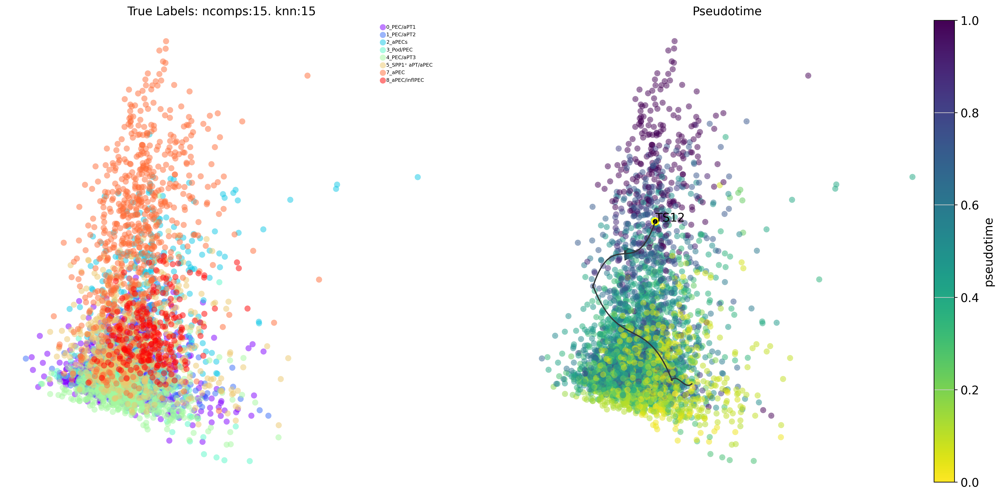

In [21]:
fig, ax, ax1 = via.plot_trajectory_curves(via_object=v0, embedding = embedding, draw_all_curves=False)

In [22]:
v0.embedding = adata.obsm["X_diffmap"]

2025-10-31 13:55:56.437244	Marker_lineages: [12]
2025-10-31 13:55:56.437552	Automatically setting embedding to via_object.embedding
2025-10-31 13:55:56.439050	The number of components in the original full graph is 1
2025-10-31 13:55:56.439068	For downstream visualization purposes we are also constructing a low knn-graph 
2025-10-31 13:56:01.421103	Check sc pb 1.0 
f getting majority comp
2025-10-31 13:56:01.739663	Cluster path on clustergraph starting from Root Cluster 67 to Terminal Cluster 12: [67, 23, 9, 27, 26, 0, 8, 12]
setting vmin to 1.0
2025-10-31 13:56:01.790236	Revised Cluster level path on sc-knnGraph from Root Cluster 67 to Terminal Cluster 12 along path: [33]


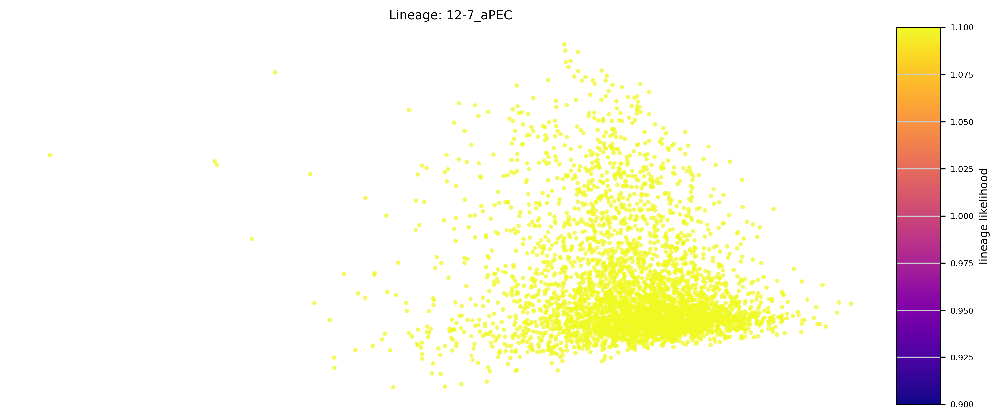

In [23]:
fig, axs= via.plot_sc_lineage_probability(via_object=v0, marker_lineages=v0.terminal_clusters) #marker_lineages=v0.terminal_clusters to plot all
fig.set_size_inches(12,5)

branches [12]


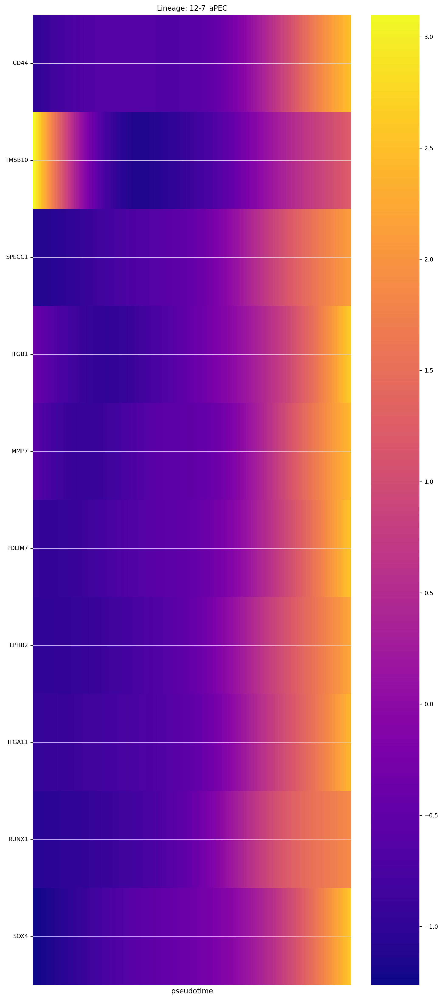

In [24]:
fig, axs = via.plot_gene_trend_heatmaps(via_object=v0, df_gene_exp=df_magic, cmap='plasma')
fig.set_size_inches(10,25)

In [25]:
adata.obs_keys

<bound method AnnData.obs_keys of AnnData object with n_obs × n_vars = 4032 × 21840
    obs: 'donor_id', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'Sample', 'Group', 'date_of_biopsy_h5ad', 'ACEi', 'AT2i', 'Statin', 'corticosteroids_h5ad', 'region', 'RNAversion', 'nCounts_RNA', 'nFeatures_RNA', 'percMT_RNA', 'is_cell', 'QC1', 'pANN', 'DF', 'sclust_A', 'sclust_B', 'sclust_C', 'sclust_D', 'sclust_E', 'clust_A', 'clust_B', 'clust_C', 'clust_D', 'clust_E', 'predicted.annotation.l3.score', 'predicted.annotation.l3', 'predicted.annotation.l3.MappingScore', 'predicted.annotation.l1', 'predicted.annotation.l2', 'unfiltered_Doublets', 'leiden01', 'leiden03', 'leiden02', 'leiden04', 'subcluster_01_do_not_use', 'subcluster_02_do_not_use', 'subcluster_03_do_not_use', 'Main_Cluster_do_not_use', 'Cell_types_KPMP_do_not_use', 'Cell_types_Subclustering_do_not_use', 'Cell_types_Subclustering2_do_not_use', 'barcode_sample', 'main_class', 'subcluster', 'Study', 'library_id', 'percent.er'

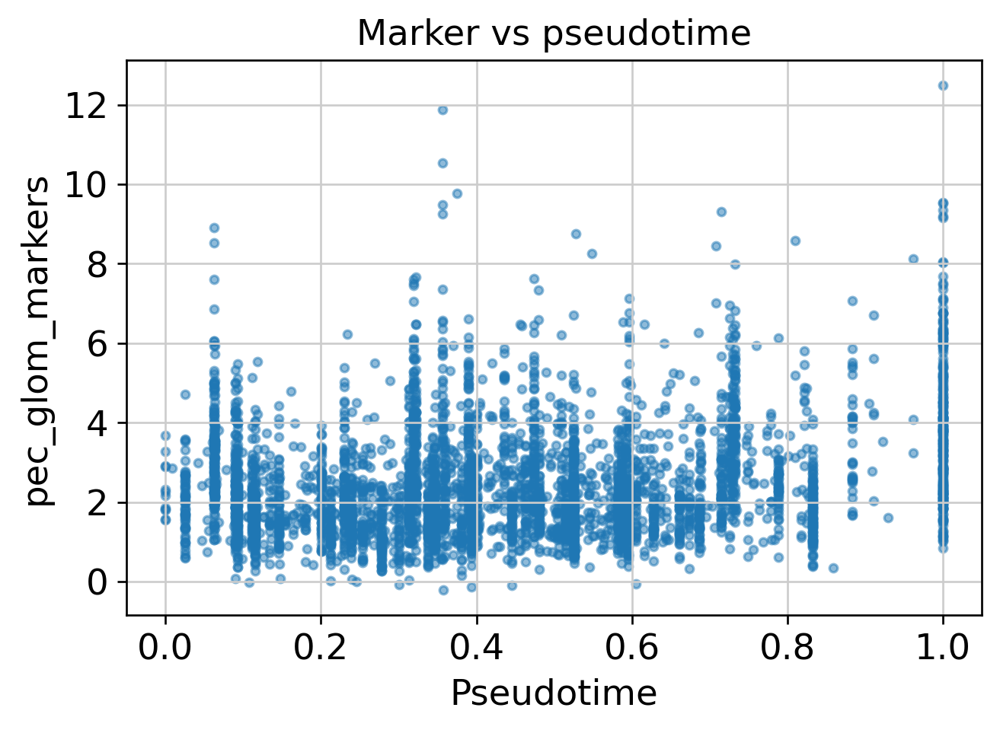

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# extract pseudotime and marker values
pseudotime = np.array(v0.single_cell_pt_markov)
marker = adata.obs['pec_glom_markers'].values

# scatter plot marker vs pseudotime
plt.figure(figsize=(6,4))
plt.scatter(pseudotime, marker, s=10, alpha=0.5)
plt.xlabel('Pseudotime'); plt.ylabel('pec_glom_markers')
plt.title('Marker vs pseudotime')
plt.show()


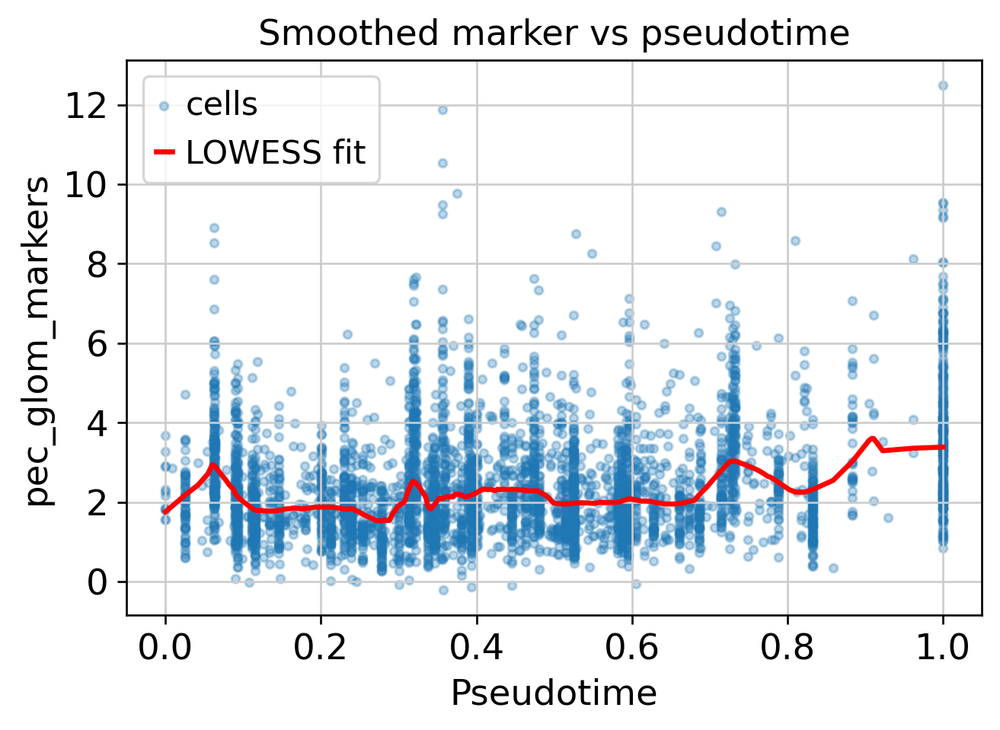

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

pseudotime = np.array(v0.single_cell_pt_markov)
marker = adata.obs['pec_glom_markers'].values

# sort by pseudotime for nicer plotting
order = np.argsort(pseudotime)
pt_sorted = pseudotime[order]
marker_sorted = marker[order]

# LOWESS smoothing
smoothed = sm.nonparametric.lowess(marker_sorted, pt_sorted, frac=0.1)

plt.figure(figsize=(6,4))
plt.scatter(pt_sorted, marker_sorted, s=10, alpha=0.3, label="cells")
plt.plot(smoothed[:,0], smoothed[:,1], color="red", linewidth=2, label="LOWESS fit")
plt.xlabel("Pseudotime")
plt.ylabel("pec_glom_markers")
plt.legend()
plt.title("Smoothed marker vs pseudotime")
plt.show()


In [28]:
import pandas as pd

# Extract pseudotime from VIA object
pt_series = pd.Series(v0.single_cell_pt_markov, index=adata.obs_names, name="pseudotime")

print(pt_series.head())


index
K89_AAAGGATCAACCGACC-1-0    0.586862
K89_AAAGGGCGTGGGTATG-1-0    0.090427
K89_AAAGGTATCCTCGATC-1-0    0.393463
K89_AACCTGACACAACATC-1-0    1.000000
K89_AAGTGAAGTAGTATAG-1-0    0.595905
Name: pseudotime, dtype: float64


In [29]:
df_magic_plot = v0.do_impute(df, magic_steps=3)

# Ensure same index as pseudotime
df_magic_plot.index = adata.obs_names

# Now correlations work
corrs_magic = df_magic_plot.corrwith(pt_series, axis=0).dropna()
top_genes_magic = corrs_magic.sort_values(ascending=False).head(20)
print(top_genes_magic)


shape of transition matrix raised to power 3 (4032, 4032)
Series([], dtype: float64)


In [30]:
df_magic = v0.do_impute(df, magic_steps=3, gene_list=adata.var_names.tolist())


shape of transition matrix raised to power 3 (4032, 4032)


In [31]:
df_magic = v0.do_impute(df, magic_steps=3, gene_list = adata.var_names)
print(type(df_magic))
print(df_magic.shape)
print(df_magic.head())


shape of transition matrix raised to power 3 (4032, 4032)
<class 'pandas.core.frame.DataFrame'>
(4032, 21840)
                          MIR1302-2HG  OR4F5  LINC01409  FAM87B  LINC01128  \
index                                                                        
K89_AAAGGATCAACCGACC-1-0          0.0    0.0   0.098843     0.0   0.128257   
K89_AAAGGGCGTGGGTATG-1-0          0.0    0.0   0.014959     0.0   0.017115   
K89_AAAGGTATCCTCGATC-1-0          0.0    0.0   0.064326     0.0   0.028878   
K89_AACCTGACACAACATC-1-0          0.0    0.0   0.275657     0.0   0.058619   
K89_AAGTGAAGTAGTATAG-1-0          0.0    0.0   0.155913     0.0   0.023533   

                          LINC00115    FAM41C  LINC02593    SAMD11     NOC2L  \
index                                                                          
K89_AAAGGATCAACCGACC-1-0   0.000000  0.000000   0.014350  0.078335  0.096533   
K89_AAAGGGCGTGGGTATG-1-0   0.000000  0.021968   0.000267  0.034959  0.051694   
K89_AAAGGTATCCTCGATC-1-

In [32]:
common = adata.obs_names.intersection(pt_series.index)
common

Index(['K89_AAAGGATCAACCGACC-1-0', 'K89_AAAGGGCGTGGGTATG-1-0',
       'K89_AAAGGTATCCTCGATC-1-0', 'K89_AACCTGACACAACATC-1-0',
       'K89_AAGTGAAGTAGTATAG-1-0', 'K89_AATCACGCACCTATCC-1-0',
       'K89_AATCGACGTGCTCCGA-1-0', 'K89_AATGCCAGTTTCGTAG-1-0',
       'K89_AATTTCCCATTCACCC-1-0', 'K89_ACAAGCTCAGTAGAAT-1-0',
       ...
       'KB66_GGTGTTATCACGTAGT-1-1', 'KB66_GTGCTTCTCAGACCCG-1-1',
       'KB66_TAACGACAGAAGCCTG-1-1', 'KB66_TCAAGACGTCTTCTAT-1-1',
       'KB66_TCAGTGAAGGCTGAAC-1-1', 'KB66_TCGATTTAGAACAGGA-1-1',
       'KB66_TCGCTCATCTCTGAGA-1-1', 'KB66_TGTTCTATCGCTTGCT-1-1',
       'KB66_TTTGGTTAGCGAGAAA-1-1', 'KB68_AGCGTATTCGGCTCTT-1-1'],
      dtype='object', name='index', length=4032)

In [33]:
import pandas as pd
import numpy as np

# 0) Run your imputation
df_magic_plot = v0.do_impute(df, magic_steps=3, gene_list=adata.var_names)
print("Imputed shape:", df_magic_plot.shape)

# 1) Set index to cell IDs from AnnData (ensure string type to avoid category mismatch)
df_magic_plot.index = pd.Index(adata.obs_names.astype(str), name="cell_id")

# 2) Prepare pseudotime series (ensure index type matches and values are numeric)
pt_series = pt_series.copy()
pt_series.index = pt_series.index.astype(str)
pt_series = pd.to_numeric(pt_series, errors="coerce")

print("\n=== Basic checks ===")
print("df_magic_plot shape:", df_magic_plot.shape)
print("pt_series length:", len(pt_series))
print("df index unique:", df_magic_plot.index.is_unique)
print("pt index unique:", pt_series.index.is_unique)
print("pt dtype:", pt_series.dtype)
print("pt min/max:", pt_series.min(), pt_series.max())

# 3) Check overlap
common = df_magic_plot.index.intersection(pt_series.index)
print("\nOverlap count:", len(common))
if len(common) == 0:
    # Show examples to understand mismatch
    print("Example df cell IDs (first 5):", df_magic_plot.index[:5].tolist())
    print("Example pt cell IDs (first 5):", pt_series.index[:5].tolist())
    raise ValueError("No overlapping cell IDs between MAGIC result and pseudotime series.")

# 4) Align both sides to common cells
df_magic_aligned = df_magic_plot.loc[common]
pt_aligned = pt_series.loc[common]

# 5) Ensure expression is numeric and inspect NaNs
non_numeric_cols = df_magic_aligned.columns[~df_magic_aligned.dtypes.apply(np.issubdtype, args=(np.number,))]
if len(non_numeric_cols) > 0:
    print("\nConverting non-numeric columns to numeric (coerce):", len(non_numeric_cols))
    df_magic_aligned = df_magic_aligned.apply(pd.to_numeric, errors="coerce")

nan_frac = df_magic_aligned.isna().mean()
nan_summary = nan_frac.describe()
print("\nNaN fraction per column summary:\n", nan_summary)

# Optionally drop columns that are all-NaN or zero variance (which yield NaN correlations)
all_nan_cols = df_magic_aligned.columns[df_magic_aligned.isna().all()]
if len(all_nan_cols) > 0:
    print("Dropping all-NaN columns:", len(all_nan_cols))
    df_magic_aligned = df_magic_aligned.drop(columns=all_nan_cols)

# 6) Check pseudotime variance (constant series -> NaN correlations)
pt_var = pt_aligned.var()
print("\nPseudotime variance:", pt_var)
if pd.isna(pt_var) or pt_var == 0:
    raise ValueError("Pseudotime has zero or undefined variance; correlations will be NaN.")

# 7) Compute correlations safely
corrs_magic = df_magic_aligned.corrwith(pt_aligned, axis=0)

# 8) Final cleanup and reporting
corrs_magic = corrs_magic.dropna()
print("\nNumber of genes with valid correlations:", len(corrs_magic))

if len(corrs_magic) == 0:
    # Provide diagnostics to investigate further
    print("\nDiagnostics:")
    print("Example common IDs:", list(common[:5]))
    # Check a couple of columns against pt to see if they are numeric and varying
    sample_cols = df_magic_aligned.columns[:5]
    print("Sample columns:", sample_cols.tolist())
    print("Sample col dtypes:", df_magic_aligned[sample_cols].dtypes.tolist())
    print("Sample col variances:", df_magic_aligned[sample_cols].var(numeric_only=True).tolist())
    # Correlate a single column manually
    for c in sample_cols:
        s = df_magic_aligned[c]
        r = s.corr(pt_aligned)
        print(f"Manual corr {c}: {r}")
else:
    top_genes_magic = corrs_magic.sort_values(ascending=False).head(20)
    print("\nTop correlating genes:")
    print(top_genes_magic)

shape of transition matrix raised to power 3 (4032, 4032)
Imputed shape: (4032, 21840)

=== Basic checks ===
df_magic_plot shape: (4032, 21840)
pt_series length: 4032
df index unique: True
pt index unique: True
pt dtype: float64
pt min/max: 0.0 1.0

Overlap count: 4032

NaN fraction per column summary:
 count    21840.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
dtype: float64

Pseudotime variance: 0.06663045851682695

Number of genes with valid correlations: 19788

Top correlating genes:
PXDN         0.771739
MACF1        0.757893
SON          0.751050
ANKRD36C     0.750930
EFCAB13      0.747483
SF3B1        0.741423
SP100        0.740115
LINC00342    0.738253
NSUN6        0.736796
RNF213       0.732076
ASCC3        0.730636
HERC2        0.728806
TPP2         0.728403
PARP14       0.726174
GOLGA8B      0.724722
ILK          0.724317
VPS13C       0.724293
HEATR1       0.721490
ARHGAP29     0.721236
SYNJ2       

In [38]:
adata

AnnData object with n_obs × n_vars = 4032 × 21840
    obs: 'donor_id', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'Sample', 'Group', 'date_of_biopsy_h5ad', 'ACEi', 'AT2i', 'Statin', 'corticosteroids_h5ad', 'region', 'RNAversion', 'nCounts_RNA', 'nFeatures_RNA', 'percMT_RNA', 'is_cell', 'QC1', 'pANN', 'DF', 'sclust_A', 'sclust_B', 'sclust_C', 'sclust_D', 'sclust_E', 'clust_A', 'clust_B', 'clust_C', 'clust_D', 'clust_E', 'predicted.annotation.l3.score', 'predicted.annotation.l3', 'predicted.annotation.l3.MappingScore', 'predicted.annotation.l1', 'predicted.annotation.l2', 'unfiltered_Doublets', 'leiden01', 'leiden03', 'leiden02', 'leiden04', 'subcluster_01_do_not_use', 'subcluster_02_do_not_use', 'subcluster_03_do_not_use', 'Main_Cluster_do_not_use', 'Cell_types_KPMP_do_not_use', 'Cell_types_Subclustering_do_not_use', 'Cell_types_Subclustering2_do_not_use', 'barcode_sample', 'main_class', 'subcluster', 'Study', 'library_id', 'percent.er', 'percent.mt', 'subclass.l2', 'su

In [39]:
# === Pseudotime heatmap (MAGIC, binned, minimal filter, peak-order, z-score & clipped) ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import issparse

def plot_pseudotime_heatmap_magic(
    adata,
    v0,
    nbins=200,                    # number of pseudotime bins
    min_pct=0.01,                 # minimal filter: keep genes expressed in >= 1% of cells
    smoothing_window=7,           # rolling window (bins) for smoothing; must be odd for symmetry ideally
    z_clip=2.0,                   # clip z-scores to [-z_clip, z_clip]
    annotate_every=100,           # y-axis tick label every N genes
    highlight_genes=None,         # genes to annotate with lines/labels
    min_cells_per_bin=5,          # drop bins with very few cells (after qcut)
    cmap='plasma',               # heatmap colormap
    output_pdf="pseudotime_heatmap_magic_peakorder.pdf",
    figure_width_in=None,         # figure width in inches; if None, auto
    figure_height_in=None         # figure height in inches; if None, auto (can get big)
):
    # 1) Pseudotime as a Series aligned to cells
    pt = pd.Series(np.asarray(v0.single_cell_pt_markov).ravel(), index=adata.obs_names, name="pseudotime").astype(float)
    if pt.isna().any():
        raise ValueError("Pseudotime contains NaNs. Please inspect v0.single_cell_pt_markov.")

    # 2) Minimal gene filter by fraction of non-zero expression in adata.X
    X = adata.X
    n_cells = adata.n_obs
    var_names = np.array(adata.var_names)

    if issparse(X):
        nonzero_frac = X.getnnz(axis=0) / n_cells
        nonzero_frac = np.asarray(nonzero_frac).ravel()
    else:
        X_dense = np.asarray(X)
        nonzero_frac = (X_dense > 0).sum(axis=0) / n_cells

    gene_mask = nonzero_frac >= min_pct
    genes_keep = var_names[gene_mask]
    if len(genes_keep) == 0:
        raise ValueError(f"No genes passed the minimal filter (min_pct={min_pct}). Try lowering min_pct.")

    print(f"[Info] Minimal filter: {len(genes_keep)}/{len(var_names)} genes kept (>= {min_pct*100:.1f}% non-zero).")

    # 3) Build raw DataFrame for MAGIC input with only kept genes (saves memory)
    if issparse(X):
        df_raw = pd.DataFrame(X[:, gene_mask].toarray(), index=adata.obs_names, columns=genes_keep)
    else:
        df_raw = pd.DataFrame(np.asarray(X)[:, gene_mask], index=adata.obs_names, columns=genes_keep)

    # 4) MAGIC imputation via VIA helper
    print("[Info] Running MAGIC imputation on filtered genes...")
    df_magic = v0.do_impute(df_raw, magic_steps=3, gene_list=list(genes_keep))
    # Ensure index is cells
    df_magic.index = df_raw.index

    # 5) Pseudotime binning (quantile bins -> more balanced, fewer empty bins)
    try:
        bin_codes = pd.qcut(pt, q=nbins, labels=False, duplicates='drop')
    except Exception as e:
        print(f"[Warn] qcut failed ({e}). Falling back to equal-width bins.")
        bin_codes = pd.cut(pt, bins=nbins, labels=False, include_lowest=True)

    # Drop bins with too few cells
    counts_per_bin = bin_codes.value_counts().sort_index()
    keep_bins = counts_per_bin.index[counts_per_bin >= min_cells_per_bin]
    if len(keep_bins) < 5:
        print("[Warn] Very few bins have enough cells. Consider reducing nbins or min_cells_per_bin.")
    keep_mask = bin_codes.isin(keep_bins)
    bin_codes_kept = bin_codes[keep_mask]
    df_magic_kept = df_magic.loc[keep_mask]

    # Aggregate per bin (mean)
    df_magic_kept = df_magic_kept.assign(__bin__=bin_codes_kept.values)
    expr_bins = df_magic_kept.groupby("__bin__").mean(numeric_only=True)   # shape: n_bins_kept x n_genes_kept
    expr_bins = expr_bins.sort_index()
    n_bins_kept = expr_bins.shape[0]
    print(f"[Info] Aggregated into {n_bins_kept} bins (after dropping bins with < {min_cells_per_bin} cells).")

    # 6) Smooth along pseudotime (rolling mean across bins)
    from scipy.signal import savgol_filter

    # Replace the rolling mean in your function with this:
    expr_sm = pd.DataFrame(
        savgol_filter(expr_bins.values, window_length=9, polyorder=2, axis=0, mode='interp'),
        index=expr_bins.index, columns=expr_bins.columns
    )

    # 7) Z-score per gene across bins; drop genes with zero variance
    mu = expr_sm.mean(axis=0)
    sigma = expr_sm.std(axis=0)
    var_ok = sigma > 0
    if var_ok.sum() == 0:
        raise ValueError("All genes have zero variance across bins after smoothing. Check inputs.")
    expr_sm = expr_sm.loc[:, var_ok.index[var_ok]]
    mu = mu[var_ok]
    sigma = sigma[var_ok]

    Z = (expr_sm - mu) / sigma
    Z = Z.clip(lower=-z_clip, upper=z_clip)

    # 8) Peak-order genes by the bin index of their (smoothed) max expression
    # Note: Z rows = bins, columns = genes
    peak_bin_idx = Z.idxmax(axis=0)  # Series: gene -> bin label
    gene_order = peak_bin_idx.sort_values(kind='mergesort').index.tolist()

    # 9) Sorted matrix (genes as rows, bins as columns)
    Z_sorted = Z.loc[:, gene_order].T  # shape: n_genes x n_bins
    n_genes_plot, n_bins_plot = Z_sorted.shape[0], Z_sorted.shape[1]

    # 10) Figure size heuristics (PDF, rasterized image to keep size manageable)
    if figure_width_in is None:
        figure_width_in = max(6.0, min(14.0, n_bins_plot * 0.03))   # ~0.03 inches per bin
    if figure_height_in is None:
        # Keep it large but capped; cells will be tiny
        figure_height_in = max(8.0, min(60.0, n_genes_plot * 0.004))  # ~0.004 inches per gene (cap at 60")

    fig, ax = plt.subplots(figsize=(figure_width_in, figure_height_in))
    im = ax.imshow(
        Z_sorted.values,
        aspect='auto',
        interpolation='nearest',
        cmap=cmap,
        vmin=-z_clip, vmax=z_clip,
        origin='lower'
    )
    im.set_rasterized(True)  # rasterize the heavy image inside the PDF

    # Colorbar
    cbar = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.02)
    cbar.set_label("Z-score (per gene across pseudotime)")

    # Axes labels and ticks
    ax.set_xlabel("Pseudotime (binned)")
    ax.set_ylabel("Genes (ordered by peak pseudotime)")

    # X ticks at 0/25/50/75/100%
    x_ticks = [0, max(0, n_bins_plot//4), max(0, n_bins_plot//2), max(0, (3*n_bins_plot)//4), n_bins_plot-1]
    x_labels = ["0%", "25%", "50%", "75%", "100%"]
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels, rotation=0)

    # Y ticks every 'annotate_every' genes (numeric ranks)
    if annotate_every and n_genes_plot > annotate_every:
        y_ticks = np.arange(0, n_genes_plot, annotate_every)
        ax.set_yticks(y_ticks)
        ax.set_yticklabels([str(i) for i in y_ticks], fontsize=6)
    else:
        ax.set_yticks([])

    # Gridlines for readability every 'annotate_every' genes
    if annotate_every and n_genes_plot > annotate_every:
        for y in np.arange(0, n_genes_plot, annotate_every):
            ax.axhline(y - 0.5, color='white', lw=0.2, alpha=0.3, zorder=3)

    # Highlight your earlier list of genes
    if highlight_genes is None:
        highlight_genes = [
            'CD44','TMSB10','SPECC1','ITGB1','MMP7',
            'PDLIM7','EPHB2','ITGA11','RUNX1','SOX4'
        ]
    present_highlights = [g for g in highlight_genes if g in Z_sorted.index]
    if len(present_highlights) > 0:
        # Make extra left margin for labels
        plt.subplots_adjust(left=0.22)
        for g in present_highlights:
            y = Z_sorted.index.get_loc(g)
            ax.axhline(y, color='red', lw=0.4, alpha=0.7)
            ax.text(
                -0.02, y, g,
                va='center', ha='right', color='red', fontsize=7,
                transform=ax.get_yaxis_transform()  # x in axes frac, y in data coords
            )
        print(f"[Info] Highlighted {len(present_highlights)} genes: {present_highlights}")
    else:
        print("[Info] None of the highlight genes were present after filtering/z-score step.")

    # Tight layout and save
    plt.tight_layout()
    fig.savefig(output_pdf, bbox_inches='tight')
    plt.close(fig)

    # Optional: return objects for further use
    peak_table = pd.DataFrame({
        "peak_bin": peak_bin_idx[gene_order].values,
        "gene": gene_order
    }).set_index("gene")
    return {
        "Z_sorted": Z_sorted,           # genes x bins
        "peak_order": gene_order,       # list of genes in peak order
        "peak_table": peak_table,       # DataFrame with peak bin
        "bins_count": n_bins_plot,
        "genes_count": n_genes_plot,
        "output_pdf": output_pdf
    }

# ---- Run with your dataset/VIA object ----
result = plot_pseudotime_heatmap_magic(
    adata=adata,
    v0=v0,
    nbins=200,
    min_pct=0.01,
    smoothing_window=7,
    z_clip=2.0,
    annotate_every=None,
    highlight_genes=[
        'CD44','TMSB10','SPECC1','ITGB1','MMP7',
        'PDLIM7','EPHB2','ITGA11','RUNX1','SOX4'
    ],
    min_cells_per_bin=5,
    cmap='plasma',
    output_pdf="pseudotime_heatmap_magic_peakorder.pdf"
)

print(f"Saved PDF to: {result['output_pdf']}")
print(f"Genes plotted: {result['genes_count']}, bins plotted: {result['bins_count']}")

[Info] Minimal filter: 13413/21840 genes kept (>= 1.0% non-zero).
[Info] Running MAGIC imputation on filtered genes...
shape of transition matrix raised to power 3 (4032, 4032)
[Info] Aggregated into 91 bins (after dropping bins with < 5 cells).
[Info] Highlighted 10 genes: ['CD44', 'TMSB10', 'SPECC1', 'ITGB1', 'MMP7', 'PDLIM7', 'EPHB2', 'ITGA11', 'RUNX1', 'SOX4']
Saved PDF to: pseudotime_heatmap_magic_peakorder.pdf
Genes plotted: 13413, bins plotted: 91


Fraction of genes peaking in last 10% of pseudotime: 57.23%


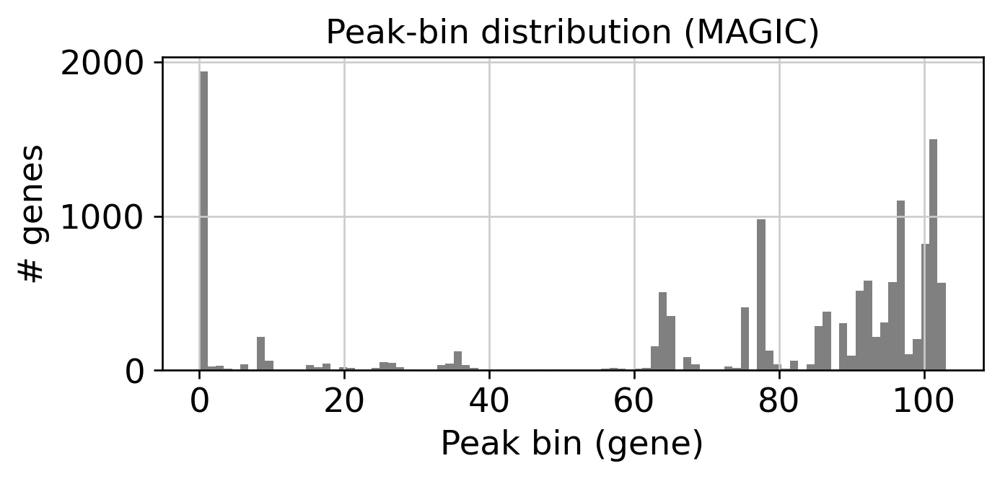

In [40]:
import numpy as np, matplotlib.pyplot as plt

peak_bins = result["peak_table"]["peak_bin"].astype(int)
n_bins = result["bins_count"]
frac_last10 = (peak_bins >= int(0.9 * (n_bins-1))).mean()
print(f"Fraction of genes peaking in last 10% of pseudotime: {frac_last10:.2%}")

plt.figure(figsize=(6,3))
plt.hist(peak_bins, bins=n_bins, color='gray')
plt.xlabel("Peak bin (gene)"); plt.ylabel("# genes"); plt.title("Peak-bin distribution (MAGIC)")
plt.tight_layout(); plt.show()

In [43]:
import scanpy as sc

hvg_info = sc.pp.highly_variable_genes(adata, n_top_genes=1000, inplace=False)
hv_mask = hvg_info["highly_variable"].values if isinstance(hvg_info, pd.DataFrame) else adata.var["highly_variable"].values

adata_hvg = adata[:, hv_mask].copy()
result_hvg = plot_pseudotime_heatmap_magic(
    adata=adata_hvg,
    v0=v0,
    nbins=200,
    min_pct=0.00,          
    smoothing_window=7,
    z_clip=2.0,
    annotate_every=None,
    output_pdf="pseudotime_heatmap_magic_peakorder_HVGs.pdf"
)

[Info] Minimal filter: 1000/1000 genes kept (>= 0.0% non-zero).
[Info] Running MAGIC imputation on filtered genes...
shape of transition matrix raised to power 3 (4032, 4032)
[Info] Aggregated into 91 bins (after dropping bins with < 5 cells).
[Info] Highlighted 2 genes: ['EPHB2', 'SOX4']


In [44]:
# Reuse the same binning as your heatmap run
pt = pd.Series(np.asarray(v0.single_cell_pt_markov).ravel(), index=adata.obs_names, name="pseudotime").astype(float)
bin_codes = pd.qcut(pt, q=result["bins_count"], labels=False, duplicates='drop')

# Compute per-bin means on MAGIC for the same genes as in the heatmap
from scipy.sparse import issparse
genes = result["Z_sorted"].index
X = adata[:, genes].X
if issparse(X): X = X.toarray()
df_magic = pd.DataFrame(X, index=adata.obs_names, columns=genes)  # if you still have the MAGIC matrix, use it instead
df_magic_b = df_magic.assign(__bin__=bin_codes.values).groupby("__bin__").mean(numeric_only=True).sort_index()
df_magic_b_sm = df_magic_b.rolling(window=7, center=True, min_periods=1).mean()

# Dynamic range per gene and filtering
dyn = df_magic_b_sm.quantile(0.95, axis=0) - df_magic_b_sm.quantile(0.05, axis=0)
thr = np.quantile(dyn, 0.5)     # keep top 50% by dynamic range; make stricter if needed
keep = dyn[dyn >= thr].index
dfb = df_magic_b_sm[keep]

# Z-score and center-of-mass ordering (positive activity)
Z = ((dfb - dfb.mean(0)) / dfb.std(0)).clip(-2, 2)
pos = Z.clip(lower=0)
weights = pos.values
bins = np.arange(len(Z.index)).reshape(-1,1)
com = (weights * bins).sum(axis=0) / np.maximum(weights.sum(axis=0), 1e-9)
order = np.argsort(com)
Z_sorted_com = pd.DataFrame(Z.values[:, order].T, index=pos.columns[order], columns=Z.index)

# Plot a quick PDF with COM order
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, min(50, 0.004*Z_sorted_com.shape[0] + 6)))
im = ax.imshow(Z_sorted_com.values, aspect='auto', origin='lower', vmin=-2, vmax=2, cmap='viridis')
im.set_rasterized(True)
plt.colorbar(im, ax=ax, fraction=0.02, pad=0.02, label="Z-score")
ax.set_xlabel("Pseudotime (binned)"); ax.set_ylabel("Genes (COM order)")
plt.tight_layout()
fig.savefig("pseudotime_heatmap_magic_COMorder_dynamicRange.pdf", bbox_inches='tight'); plt.close(fig)

In [45]:
import numpy as np
import pandas as pd
import decoupler as dc
from statsmodels.stats.multitest import multipletests
from scipy.stats import spearmanr

# 1) Add pseudotime to adata.obs
adata.obs['pseudotime_via'] = pd.Series(
    np.asarray(v0.single_cell_pt_markov).ravel(),
    index=adata.obs_names
).astype(float)
# Optional: 0-1 scaling
pt = adata.obs['pseudotime_via']
adata.obs['pseudotime_via_scaled'] = (pt - pt.min()) / (pt.max() - pt.min() + 1e-12)

# 2) Load Hallmark gene sets (choose organism to match your gene symbols)
hm = dc.op.hallmark(organism='human')  # or 'mouse'

# Ensure the resource has the expected columns (source/target/weight)
rename_map = {}
if 'source' not in hm.columns:
    if 'geneset' in hm.columns: rename_map['geneset'] = 'source'
    if 'set' in hm.columns: rename_map['set'] = 'source'
if 'target' not in hm.columns:
    if 'gene' in hm.columns: rename_map['gene'] = 'target'
    if 'genes' in hm.columns: rename_map['genes'] = 'target'
if rename_map:
    hm = hm.rename(columns=rename_map)
if 'weight' not in hm.columns:
    hm['weight'] = 1.0

# Intersect with genes present in your data (make sure casing matches)
genes_present = set(adata.var_names.astype(str))
hm = hm[hm['target'].astype(str).isin(genes_present)]

# Keep pathways with sufficient coverage
min_genes_per_set = 5
counts = hm.groupby('source')['target'].nunique()
hm_use = hm[hm['source'].isin(counts[counts >= min_genes_per_set].index)].copy()
print(f"Hallmarks retained: {hm_use['source'].nunique()} sets; "
      f"median mapped genes per set: {int(counts[counts >= min_genes_per_set].median())}")

# 3) Optional: use MAGIC-imputed expression if you already computed it for all genes
# If you have a full MAGIC matrix aligned to adata (cells x genes), attach as a layer:
# adata.layers['magic'] = df_magic.loc[adata.obs_names, adata.var_names].to_numpy().astype(np.float32)
use_magic_layer = 'magic' in adata.layers

# 4) Run ULM on the AnnData directly
dc.mt.ulm(
    adata,
    net=hm,
)

Hallmarks retained: 50 sets; median mapped genes per set: 173


In [46]:
adata

AnnData object with n_obs × n_vars = 4032 × 21840
    obs: 'donor_id', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'Sample', 'Group', 'date_of_biopsy_h5ad', 'ACEi', 'AT2i', 'Statin', 'corticosteroids_h5ad', 'region', 'RNAversion', 'nCounts_RNA', 'nFeatures_RNA', 'percMT_RNA', 'is_cell', 'QC1', 'pANN', 'DF', 'sclust_A', 'sclust_B', 'sclust_C', 'sclust_D', 'sclust_E', 'clust_A', 'clust_B', 'clust_C', 'clust_D', 'clust_E', 'predicted.annotation.l3.score', 'predicted.annotation.l3', 'predicted.annotation.l3.MappingScore', 'predicted.annotation.l1', 'predicted.annotation.l2', 'unfiltered_Doublets', 'leiden01', 'leiden03', 'leiden02', 'leiden04', 'subcluster_01_do_not_use', 'subcluster_02_do_not_use', 'subcluster_03_do_not_use', 'Main_Cluster_do_not_use', 'Cell_types_KPMP_do_not_use', 'Cell_types_Subclustering_do_not_use', 'Cell_types_Subclustering2_do_not_use', 'barcode_sample', 'main_class', 'subcluster', 'Study', 'library_id', 'percent.er', 'percent.mt', 'subclass.l2', 'su

In [47]:
adata.obs.pseudotime_via.head()

index
K89_AAAGGATCAACCGACC-1-0    0.586862
K89_AAAGGGCGTGGGTATG-1-0    0.090427
K89_AAAGGTATCCTCGATC-1-0    0.393463
K89_AACCTGACACAACATC-1-0    1.000000
K89_AAGTGAAGTAGTATAG-1-0    0.595905
Name: pseudotime_via, dtype: float64

In [48]:
score = dc.pp.get_obsm(adata=adata, key="score_ulm")
score

AnnData object with n_obs × n_vars = 4032 × 50
    obs: 'donor_id', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'Sample', 'Group', 'date_of_biopsy_h5ad', 'ACEi', 'AT2i', 'Statin', 'corticosteroids_h5ad', 'region', 'RNAversion', 'nCounts_RNA', 'nFeatures_RNA', 'percMT_RNA', 'is_cell', 'QC1', 'pANN', 'DF', 'sclust_A', 'sclust_B', 'sclust_C', 'sclust_D', 'sclust_E', 'clust_A', 'clust_B', 'clust_C', 'clust_D', 'clust_E', 'predicted.annotation.l3.score', 'predicted.annotation.l3', 'predicted.annotation.l3.MappingScore', 'predicted.annotation.l1', 'predicted.annotation.l2', 'unfiltered_Doublets', 'leiden01', 'leiden03', 'leiden02', 'leiden04', 'subcluster_01_do_not_use', 'subcluster_02_do_not_use', 'subcluster_03_do_not_use', 'Main_Cluster_do_not_use', 'Cell_types_KPMP_do_not_use', 'Cell_types_Subclustering_do_not_use', 'Cell_types_Subclustering2_do_not_use', 'barcode_sample', 'main_class', 'subcluster', 'Study', 'library_id', 'percent.er', 'percent.mt', 'subclass.l2', 'subcl

In [49]:
import numpy as np
import pandas as pd
import decoupler as dc
from statsmodels.stats.multitest import multipletests
from scipy.stats import spearmanr

# 1) Add pseudotime to adata.obs
adata.obs['pseudotime_via'] = pd.Series(
    np.asarray(v0.single_cell_pt_markov).ravel(),
    index=adata.obs_names
).astype(float)
# Optional: 0-1 scaling
pt = adata.obs['pseudotime_via']
adata.obs['pseudotime_via_scaled'] = (pt - pt.min()) / (pt.max() - pt.min() + 1e-12)

# 2) Load Hallmark gene sets (choose organism to match your gene symbols)
hm = dc.op.hallmark(organism='human')  # or 'mouse'

# Ensure the resource has the expected columns (source/target/weight)
rename_map = {}
if 'source' not in hm.columns:
    if 'geneset' in hm.columns: rename_map['geneset'] = 'source'
    if 'set' in hm.columns: rename_map['set'] = 'source'
if 'target' not in hm.columns:
    if 'gene' in hm.columns: rename_map['gene'] = 'target'
    if 'genes' in hm.columns: rename_map['genes'] = 'target'
if rename_map:
    hm = hm.rename(columns=rename_map)
if 'weight' not in hm.columns:
    hm['weight'] = 1.0

# Intersect with genes present in your data (make sure casing matches)
genes_present = set(adata.var_names.astype(str))
hm = hm[hm['target'].astype(str).isin(genes_present)]

# Keep pathways with sufficient coverage
min_genes_per_set = 5
counts = hm.groupby('source')['target'].nunique()
hm_use = hm[hm['source'].isin(counts[counts >= min_genes_per_set].index)].copy()
print(f"Hallmarks retained: {hm_use['source'].nunique()} sets; "
      f"median mapped genes per set: {int(counts[counts >= min_genes_per_set].median())}")

# 3) Optional: use MAGIC-imputed expression if you already computed it for all genes
# If you have a full MAGIC matrix aligned to adata (cells x genes), attach as a layer:
# adata.layers['magic'] = df_magic.loc[adata.obs_names, adata.var_names].to_numpy().astype(np.float32)
use_magic_layer = 'magic' in adata.layers

# 4) Run ULM on the AnnData directly
dc.mt.ulm(
    adata,
    net=hm,
)
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# Reuse the Pearson helper from earlier (or paste it here if not in scope)
def pearson_cols_vs_vec(X, y):
    y = np.asarray(y, dtype=np.float64)
    n = X.shape[0]
    y_mean = y.mean()
    y_var = y.var(ddof=1)
    if sp.issparse(X):
        X = X.tocsr()
        sX = np.array(X.sum(axis=0)).ravel()
        meanX = sX / n
        sX2 = np.array(X.multiply(X).sum(axis=0)).ravel()
        varX = (sX2 - n * meanX**2) / (n - 1)
        sum_x_y = np.array(X.T @ y).ravel()
        cov = (sum_x_y - n * meanX * y_mean) / (n - 1)
    else:
        X = np.asarray(X, dtype=np.float64)
        meanX = X.mean(axis=0)
        varX = X.var(axis=0, ddof=1)
        cov = ((X - meanX).T @ (y - y_mean)) / (n - 1)
    denom = np.sqrt(varX * y_var)
    r = np.zeros_like(denom, dtype=float)
    mask = denom > 0
    r[mask] = cov[mask] / denom[mask]
    df = n - 2
    tstat = r * np.sqrt(df / np.maximum(1e-15, 1 - r**2))
    p = 2 * stats.t.sf(np.abs(tstat), df)
    return r, p

# 1) Extract ULM scores from obsm and coerce to DataFrame
M = adata.obsm['score_ulm']  # already aligned to adata.obs
if isinstance(M, pd.DataFrame):
    score_df = M.copy()
else:
    arr = M.A if sp.issparse(M) else np.asarray(M)
    # If column names are not available, create placeholders
    cols = getattr(M, 'columns', None)
    if cols is None or len(getattr(M, 'columns', [])) != arr.shape[1]:
        cols = [f'pathway_{i}' for i in range(arr.shape[1])]
    score_df = pd.DataFrame(arr, index=adata.obs_names, columns=cols)

# Optional sanity check
assert score_df.shape[0] == adata.n_obs, "ULM score rows must match n_obs."

# 2) Correlate pathway scores with pseudotime
pt = adata.obs['pseudotime_via'].astype(float).values  # or 'pseudotime_via_scaled'

# Pearson (vectorized)
r_p_ulm, p_p_ulm = pearson_cols_vs_vec(score_df.values, pt)
padj_p_ulm = multipletests(p_p_ulm, method='fdr_bh')[1]

# Spearman (few columns, do per-pathway)
r_s_ulm = []
p_s_ulm = []
for col in score_df.columns:
    r, p = spearmanr(score_df[col].values, pt)
    r_s_ulm.append(r)
    p_s_ulm.append(p)
r_s_ulm = np.array(r_s_ulm)
p_s_ulm = np.array(p_s_ulm)
padj_s_ulm = multipletests(p_s_ulm, method='fdr_bh')[1]

hallmark_corr = pd.DataFrame({
    'pathway': score_df.columns,
    'r_pearson': r_p_ulm,
    'p_pearson': p_p_ulm,
    'padj_pearson': padj_p_ulm,
    'r_spearman': r_s_ulm,
    'p_spearman': p_s_ulm,
    'padj_spearman': padj_s_ulm,
}).set_index('pathway').sort_values('r_pearson', key=np.abs, ascending=False)

print(hallmark_corr.head(20))

# (Optional) store in adata for later use
adata.uns['hallmark_pt_corr'] = hallmark_corr

Hallmarks retained: 50 sets; median mapped genes per set: 173
                                   r_pearson      p_pearson   padj_pearson  \
pathway                                                                      
OXIDATIVE_PHOSPHORYLATION          -0.435219  4.878804e-186  2.439402e-184   
MITOTIC_SPINDLE                     0.336104  4.695306e-107  1.173826e-105   
EPITHELIAL_MESENCHYMAL_TRANSITION   0.318719   7.151571e-96   1.191928e-94   
UV_RESPONSE_DN                      0.287453   1.470408e-77   1.838010e-76   
REACTIVE_OXYGEN_SPECIES_PATHWAY    -0.281990   1.375239e-74   1.375239e-73   
INFLAMMATORY_RESPONSE               0.256037   2.266245e-61   1.888537e-60   
XENOBIOTIC_METABOLISM              -0.255213   5.640278e-61   4.028770e-60   
P53_PATHWAY                        -0.237597   7.424486e-53   4.640304e-52   
ADIPOGENESIS                       -0.233654   3.978124e-51   2.210069e-50   
KRAS_SIGNALING_DN                  -0.232054   1.958805e-50   9.794027e-50   
FA

In [50]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
from scipy.stats import rankdata
from statsmodels.stats.multitest import multipletests


# Choose which pseudotime to use
pt = adata.obs['pseudotime_via'].astype(float).values  # or 'pseudotime_via_scaled'

# Helper: get expression matrix
def get_X(adata, layer=None, use_magic_if_present=True, dtype=np.float64):
    if layer is None and use_magic_if_present and 'magic' in adata.layers:
        layer = 'magic'
        print("Using adata.layers['magic'] for correlations.")
    X = adata.layers[layer] if layer is not None else adata.X
    if sp.issparse(X):
        X = X.tocsr()
    else:
        X = np.asarray(X, dtype=dtype)
    return X

# Fast, vectorized Pearson corr of all columns vs a vector (supports CSR sparse)
def pearson_cols_vs_vec(X, y):
    y = np.asarray(y, dtype=np.float64)
    n = X.shape[0]
    y_mean = y.mean()
    y_var = y.var(ddof=1)
    if sp.issparse(X):
        sX = np.array(X.sum(axis=0)).ravel()
        meanX = sX / n
        sX2 = np.array(X.multiply(X).sum(axis=0)).ravel()
        varX = (sX2 - n * meanX**2) / (n - 1)
        sum_x_y = np.array(X.T @ y).ravel()
        cov = (sum_x_y - n * meanX * y_mean) / (n - 1)
    else:
        meanX = X.mean(axis=0)
        varX = X.var(axis=0, ddof=1)
        cov = ((X - meanX).T @ (y - y_mean)) / (n - 1)
    denom = np.sqrt(varX * y_var)
    r = np.zeros_like(denom, dtype=float)
    mask = denom > 0
    r[mask] = cov[mask] / denom[mask]

    df = n - 2
    tstat = r * np.sqrt(df / np.maximum(1e-15, 1 - r**2))
    p = 2 * stats.t.sf(np.abs(tstat), df)
    return r, p

# Spearman via chunked rank transform (dense chunks), then Pearson on ranks
def spearman_cols_vs_vec_chunked(X, y, chunk_size=1000):
    y_rank = rankdata(y, method='average').astype(np.float64)
    p = X.shape[1]
    rs = np.empty(p, dtype=float)
    ps = np.empty(p, dtype=float)
    for start in range(0, p, chunk_size):
        end = min(p, start + chunk_size)
        if sp.issparse(X):
            block = X[:, start:end].toarray()
        else:
            block = np.asarray(X[:, start:end])
        ranks_block = np.empty_like(block, dtype=float)
        # Rank each column; scipy's rankdata is implemented in C, but called per-column
        for j in range(block.shape[1]):
            ranks_block[:, j] = rankdata(block[:, j], method='average')
        r_chunk, p_chunk = pearson_cols_vs_vec(ranks_block, y_rank)
        rs[start:end] = r_chunk
        ps[start:end] = p_chunk
    return rs, ps

# Compute
X = get_X(adata, layer=None, use_magic_if_present=True, dtype=np.float64)
genes = adata.var_names.astype(str)

# 1) Pearson for all genes
r_pearson, p_pearson = pearson_cols_vs_vec(X, pt)
padj_pearson = multipletests(p_pearson, method='fdr_bh')[1]

# 2) Spearman for top-k by |Pearson r| (set top_k_spearman=None to compute all)
top_k_spearman = None  # adjust as you like; set to None for all genes (slower)
if top_k_spearman is None or top_k_spearman >= X.shape[1]:
    rs, ps = spearman_cols_vs_vec_chunked(X, pt, chunk_size=800)
    r_spearman, p_spearman = rs, ps
    padj_spearman = multipletests(p_spearman, method='fdr_bh')[1]
else:
    order = np.argsort(-np.abs(r_pearson))
    take = order[:top_k_spearman]
    r_spearman = np.full(X.shape[1], np.nan, dtype=float)
    p_spearman = np.full(X.shape[1], np.nan, dtype=float)

    # Compute Spearman just for selected genes
    if sp.issparse(X):
        X_sel = X[:, take].toarray()
    else:
        X_sel = np.asarray(X[:, take])
    rs_sel, ps_sel = spearman_cols_vs_vec_chunked(X_sel, pt, chunk_size=800)
    r_spearman[take] = rs_sel
    p_spearman[take] = ps_sel
    # FDR only over tested genes
    padj_tmp = multipletests(ps_sel, method='fdr_bh')[1]
    padj_spearman = np.full(X.shape[1], np.nan, dtype=float)
    padj_spearman[take] = padj_tmp

# Assemble results
gene_corr = pd.DataFrame({
    'gene': genes,
    'r_pearson': r_pearson,
    'p_pearson': p_pearson,
    'padj_pearson': padj_pearson,
    'r_spearman': r_spearman,
    'p_spearman': p_spearman,
    'padj_spearman': padj_spearman,
}).set_index('gene').sort_values('r_pearson', key=np.abs, ascending=False)

# Top hits (you can sort by spearman if you prefer)
print(gene_corr.head(20))

          r_pearson      p_pearson   padj_pearson  r_spearman     p_spearman  \
gene                                                                           
MACF1      0.412285  2.807192e-165  6.130907e-161    0.407167  7.308313e-161   
DST        0.406282  4.168576e-160  4.552085e-156    0.387877  6.721979e-145   
DCDC2      0.405163  3.736045e-159  2.719841e-155    0.426669  4.142502e-178   
BICC1      0.400212  5.529591e-155  3.019157e-151    0.445174  1.462218e-195   
TPM1       0.398268  2.294666e-153  1.002310e-149    0.354747  7.066013e-120   
ARHGAP29   0.392552  1.136468e-148  4.136743e-145    0.385201  9.086098e-143   
PAX8       0.391961  3.433156e-148  1.071145e-144    0.404531  1.283916e-158   
CASC15     0.386211  1.432901e-143  3.911820e-140    0.354977  4.844959e-120   
GLS        0.376814  3.240473e-136  7.863549e-133    0.341790  7.137516e-111   
TRIO       0.375465  3.522727e-135  7.693636e-132    0.356660  3.041701e-121   
ABCC3      0.363654  2.565558e-126  5.09

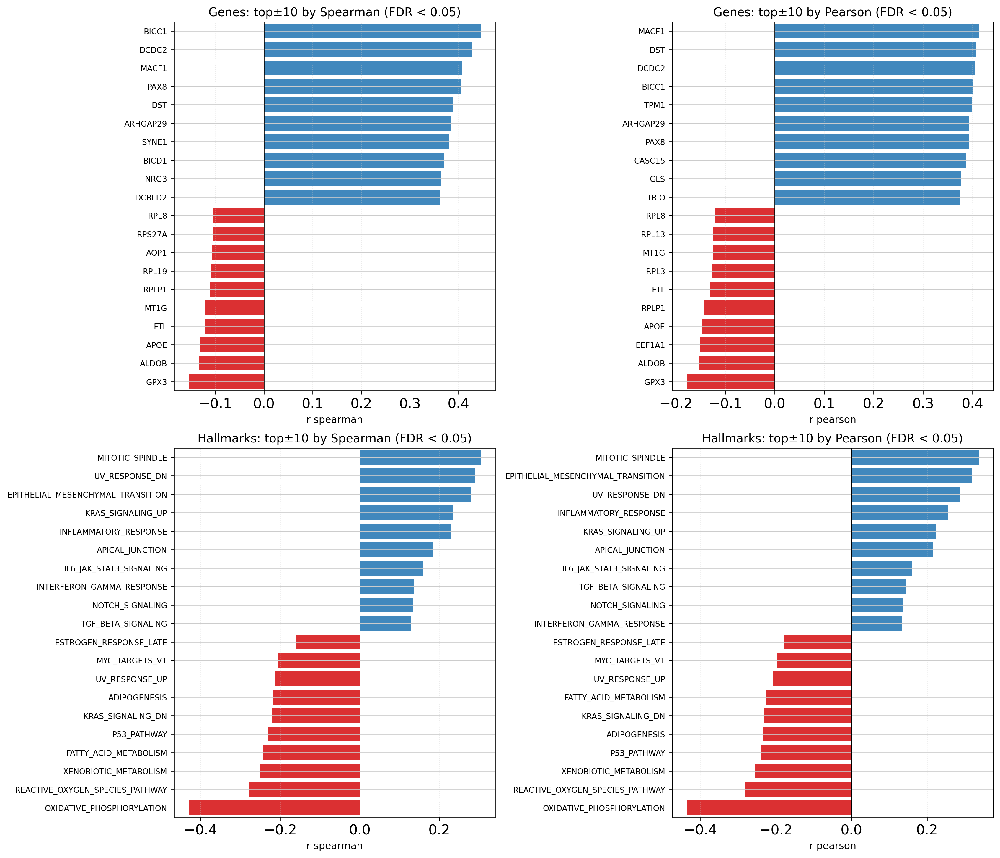

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Safety checks: require the correlation tables
assert 'gene_corr' in globals(), "gene_corr not found. Please run the gene correlation step first."
assert 'hallmark_corr' in globals(), "hallmark_corr not found. Please run the hallmark correlation step first."

def plot_top_bars(ax, df, r_col, padj_col, title, topn=10, pos_color="#2C7BB6", neg_color="#D7191C"):
    """
    Make a horizontal barplot showing top-N positive and top-N negative correlations
    among rows with padj < 0.05. df index is used as labels.
    """
    # Filter by adjusted p-value
    sub = df[[r_col, padj_col]].dropna()
    sub = sub.loc[sub[padj_col] < 0.05].copy()

    if sub.empty:
        ax.axis('off')
        ax.text(0.5, 0.5, "No features with FDR < 0.05", ha='center', va='center', fontsize=11)
        ax.set_title(title, fontsize=12)
        return

    # Select top-N positive and top-N negative by correlation
    pos = sub.nlargest(topn, r_col)
    neg = sub.nsmallest(topn, r_col)

    # Combine and order by correlation value so negatives at bottom, positives at top
    comb = pd.concat([neg, pos], axis=0)
    comb = comb[~comb.index.duplicated(keep='first')]
    comb = comb.sort_values(r_col, ascending=True)  # ascending: most negative first

    # Colors by sign
    vals = comb[r_col].values
    colors = np.where(vals >= 0, pos_color, neg_color)

    # Plot
    ax.barh(range(len(comb)), vals, color=colors, edgecolor='none', alpha=0.9)
    ax.set_yticks(range(len(comb)))
    ax.set_yticklabels(comb.index, fontsize=8)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel(r_col.replace('_', ' '), fontsize=10)
    ax.set_title(title, fontsize=12)
    ax.grid(True, axis='x', linestyle=':', alpha=0.4)

    # Optional: tighten y-limits
    ax.set_ylim(-0.5, len(comb) - 0.5)

# Build the 2×2 figure
fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)

# Gene Spearman
plot_top_bars(
    axes[0, 0],
    gene_corr,
    r_col='r_spearman',
    padj_col='padj_spearman',
    title='Genes: top±10 by Spearman (FDR < 0.05)',
    topn=10
)

# Gene Pearson
plot_top_bars(
    axes[0, 1],
    gene_corr,
    r_col='r_pearson',
    padj_col='padj_pearson',
    title='Genes: top±10 by Pearson (FDR < 0.05)',
    topn=10
)

# Hallmark Spearman
plot_top_bars(
    axes[1, 0],
    hallmark_corr,
    r_col='r_spearman',
    padj_col='padj_spearman',
    title='Hallmarks: top±10 by Spearman (FDR < 0.05)',
    topn=10
)

# Hallmark Pearson
plot_top_bars(
    axes[1, 1],
    hallmark_corr,
    r_col='r_pearson',
    padj_col='padj_pearson',
    title='Hallmarks: top±10 by Pearson (FDR < 0.05)',
    topn=10
)

plt.show()

# Optional: save to disk
# fig.savefig("pt_correlation_barplots.png", dpi=300, bbox_inches='tight')

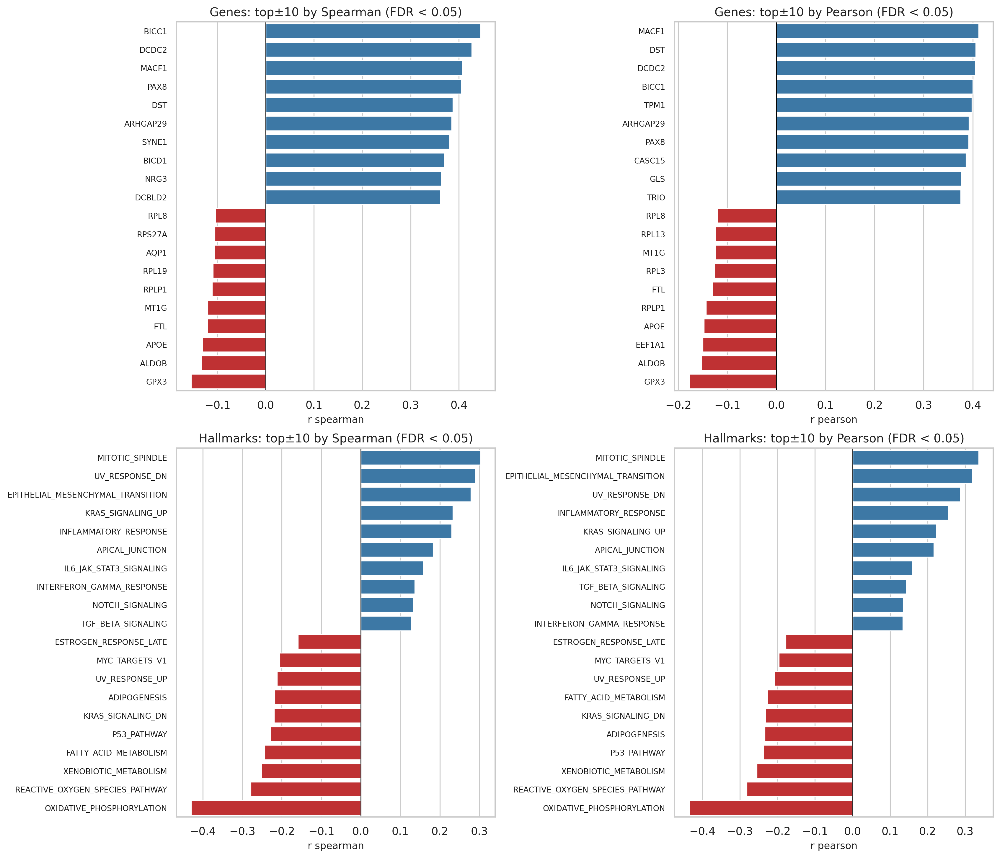

In [52]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

assert 'gene_corr' in globals(), "gene_corr not found. Run the gene correlation step first."
assert 'hallmark_corr' in globals(), "hallmark_corr not found. Run the hallmark correlation step first."

sns.set_theme(style="whitegrid", context="notebook")

POS_COLOR = "#2C7BB6"  # blue
NEG_COLOR = "#D7191C"  # red

def build_top_df(df, r_col, padj_col, topn=10):
    """
    Keep rows with padj<0.05, pick top-N positive and top-N negative by r,
    return tidy DataFrame with columns [feature, r_col, sign], preserving order.
    """
    sub = df[[r_col, padj_col]].copy()
    sub = sub.loc[sub[padj_col].notna() & (sub[padj_col] < 0.05)]

    if sub.empty:
        return pd.DataFrame(columns=["feature", r_col, "sign"])

    pos = sub.nlargest(min(topn, len(sub)), r_col)
    neg = sub.nsmallest(min(topn, len(sub)), r_col)

    comb = pd.concat([neg, pos], axis=0)
    comb = comb[~comb.index.duplicated(keep='first')]
    comb = comb.sort_values(r_col, ascending=False)

    out = comb.reset_index()
    # Robustly rename the first column (the original index) to 'feature'
    out.rename(columns={out.columns[0]: 'feature'}, inplace=True)
    out['sign'] = np.where(out[r_col] >= 0, 'positive', 'negative')
    return out

def seaborn_bar_panel(ax, df, r_col, padj_col, title, topn=10):
    plot_df = build_top_df(df, r_col=r_col, padj_col=padj_col, topn=topn)

    if plot_df.empty:
        ax.axis('off')
        ax.text(0.5, 0.5, "No features with FDR < 0.05", ha='center', va='center', fontsize=11)
        ax.set_title(title, fontsize=12)
        return

    palette = {'positive': POS_COLOR, 'negative': NEG_COLOR}
    order = plot_df['feature'].tolist()  # explicit order to respect sorting

    sns.barplot(
        data=plot_df,
        x=r_col,
        y='feature',
        hue='sign',
        dodge=False,
        palette=palette,
        errorbar=None,
        ax=ax,
        order=order
    )
    # Optional: remove legend; comment out to keep it
    leg = ax.get_legend()
    if leg is not None:
        leg.remove()

    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel(r_col.replace('_', ' '), fontsize=10)
    ax.set_ylabel("")
    ax.set_title(title, fontsize=12)
    ax.tick_params(axis='y', labelsize=8)

fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)

# Genes: Spearman
seaborn_bar_panel(
    axes[0, 0],
    gene_corr,
    r_col='r_spearman',
    padj_col='padj_spearman',
    title='Genes: top±10 by Spearman (FDR < 0.05)',
    topn=10
)

# Genes: Pearson
seaborn_bar_panel(
    axes[0, 1],
    gene_corr,
    r_col='r_pearson',
    padj_col='padj_pearson',
    title='Genes: top±10 by Pearson (FDR < 0.05)',
    topn=10
)

# Hallmarks: Spearman
seaborn_bar_panel(
    axes[1, 0],
    hallmark_corr,
    r_col='r_spearman',
    padj_col='padj_spearman',
    title='Hallmarks: top±10 by Spearman (FDR < 0.05)',
    topn=10
)

# Hallmarks: Pearson
seaborn_bar_panel(
    axes[1, 1],
    hallmark_corr,
    r_col='r_pearson',
    padj_col='padj_pearson',
    title='Hallmarks: top±10 by Pearson (FDR < 0.05)',
    topn=10
)

plt.show()
# fig.savefig("pt_correlation_barplots_seaborn.png", dpi=300, bbox_inches='tight')

In [54]:
import numpy as np
import pandas as pd
import decoupler as dc
from statsmodels.stats.multitest import multipletests
from scipy.stats import spearmanr

# 1) Add pseudotime to adata.obs
adata.obs['pseudotime_via'] = pd.Series(
    np.asarray(v0.single_cell_pt_markov).ravel(),
    index=adata.obs_names
).astype(float)
# Optional: 0-1 scaling
pt = adata.obs['pseudotime_via']
adata.obs['pseudotime_via_scaled'] = (pt - pt.min()) / (pt.max() - pt.min() + 1e-12)

# 2) Load Hallmark gene sets (choose organism to match your gene symbols)
reactome = dc.op.resource(name="MSigDB")

# Filter by canonical_marker and human
reactome = reactome[
    reactome["collection"].astype(str) == "reactome_pathways"    
]

# Remove duplicated entries
reactome = reactome[~reactome.duplicated(["geneset", "genesymbol"])]

reactome = reactome.rename(columns={"geneset": "source", "genesymbol": "target"})
reactome = reactome[["source", "target"]]


# Intersect with genes present in your data (make sure casing matches)
genes_present = set(adata.var_names.astype(str))
reactome = reactome[reactome['target'].astype(str).isin(genes_present)]

# Keep pathways with sufficient coverage
min_genes_per_set = 5
counts = reactome.groupby('source')['target'].nunique()
hm_use = reactome[reactome['source'].isin(counts[counts >= min_genes_per_set].index)].copy()
print(f"Reactome retained: {hm_use['source'].nunique()} sets; "
      f"median mapped genes per set: {int(counts[counts >= min_genes_per_set].median())}")

# 3) Optional: use MAGIC-imputed expression if you already computed it for all genes
# If you have a full MAGIC matrix aligned to adata (cells x genes), attach as a layer:
# adata.layers['magic'] = df_magic.loc[adata.obs_names, adata.var_names].to_numpy().astype(np.float32)
use_magic_layer = 'magic' in adata.layers

# 4) Run ULM on the AnnData directly
dc.mt.ulm(
    adata,
    net=reactome,
)

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# Reuse the Pearson helper from earlier (or paste it here if not in scope)
def pearson_cols_vs_vec(X, y):
    y = np.asarray(y, dtype=np.float64)
    n = X.shape[0]
    y_mean = y.mean()
    y_var = y.var(ddof=1)
    if sp.issparse(X):
        X = X.tocsr()
        sX = np.array(X.sum(axis=0)).ravel()
        meanX = sX / n
        sX2 = np.array(X.multiply(X).sum(axis=0)).ravel()
        varX = (sX2 - n * meanX**2) / (n - 1)
        sum_x_y = np.array(X.T @ y).ravel()
        cov = (sum_x_y - n * meanX * y_mean) / (n - 1)
    else:
        X = np.asarray(X, dtype=np.float64)
        meanX = X.mean(axis=0)
        varX = X.var(axis=0, ddof=1)
        cov = ((X - meanX).T @ (y - y_mean)) / (n - 1)
    denom = np.sqrt(varX * y_var)
    r = np.zeros_like(denom, dtype=float)
    mask = denom > 0
    r[mask] = cov[mask] / denom[mask]
    df = n - 2
    tstat = r * np.sqrt(df / np.maximum(1e-15, 1 - r**2))
    p = 2 * stats.t.sf(np.abs(tstat), df)
    return r, p

# 1) Extract ULM scores from obsm and coerce to DataFrame
M = adata.obsm['score_ulm']  # already aligned to adata.obs
if isinstance(M, pd.DataFrame):
    score_df = M.copy()
else:
    arr = M.A if sp.issparse(M) else np.asarray(M)
    # If column names are not available, create placeholders
    cols = getattr(M, 'columns', None)
    if cols is None or len(getattr(M, 'columns', [])) != arr.shape[1]:
        cols = [f'pathway_{i}' for i in range(arr.shape[1])]
    score_df = pd.DataFrame(arr, index=adata.obs_names, columns=cols)

# Optional sanity check
assert score_df.shape[0] == adata.n_obs, "ULM score rows must match n_obs."

# 2) Correlate pathway scores with pseudotime
pt = adata.obs['pseudotime_via'].astype(float).values  # or 'pseudotime_via_scaled'

# Pearson (vectorized)
r_p_ulm, p_p_ulm = pearson_cols_vs_vec(score_df.values, pt)
padj_p_ulm = multipletests(p_p_ulm, method='fdr_bh')[1]

# Spearman (few columns, do per-pathway)
r_s_ulm = []
p_s_ulm = []
for col in score_df.columns:
    r, p = spearmanr(score_df[col].values, pt)
    r_s_ulm.append(r)
    p_s_ulm.append(p)
r_s_ulm = np.array(r_s_ulm)
p_s_ulm = np.array(p_s_ulm)
padj_s_ulm = multipletests(p_s_ulm, method='fdr_bh')[1]

reactome_corr = pd.DataFrame({
    'pathway': score_df.columns,
    'r_pearson': r_p_ulm,
    'p_pearson': p_p_ulm,
    'padj_pearson': padj_p_ulm,
    'r_spearman': r_s_ulm,
    'p_spearman': p_s_ulm,
    'padj_spearman': padj_s_ulm,
}).set_index('pathway').sort_values('r_pearson', key=np.abs, ascending=False)

print(reactome_corr.head(20))

# (Optional) store in adata for later use
adata.uns['reactome_pt_corr'] = reactome_corr

Reactome retained: 1768 sets; median mapped genes per set: 22
                                                    r_pearson      p_pearson  \
pathway                                                                        
REACTOME_METABOLISM_OF_AMINO_ACIDS_AND_DERIVATIVES  -0.448318  1.234387e-198   
REACTOME_TRANSPORT_OF_SMALL_MOLECULES               -0.445853  3.194615e-196   
REACTOME_TRANSLATION                                -0.384526  3.109253e-142   
REACTOME_SLC_MEDIATED_TRANSMEMBRANE_TRANSPORT       -0.383978  8.439556e-142   
REACTOME_RRNA_PROCESSING                            -0.370305  2.911994e-131   
REACTOME_EUKARYOTIC_TRANSLATION_ELONGATION          -0.367394  4.390376e-129   
REACTOME_SRP_DEPENDENT_COTRANSLATIONAL_PROTEIN_...  -0.364522  5.886077e-127   
REACTOME_CELLULAR_RESPONSE_TO_STARVATION            -0.364484  6.277980e-127   
REACTOME_SELENOAMINO_ACID_METABOLISM                -0.362163  3.171679e-125   
REACTOME_AEROBIC_RESPIRATION_AND_RESPIRATORY_EL...  -0.358

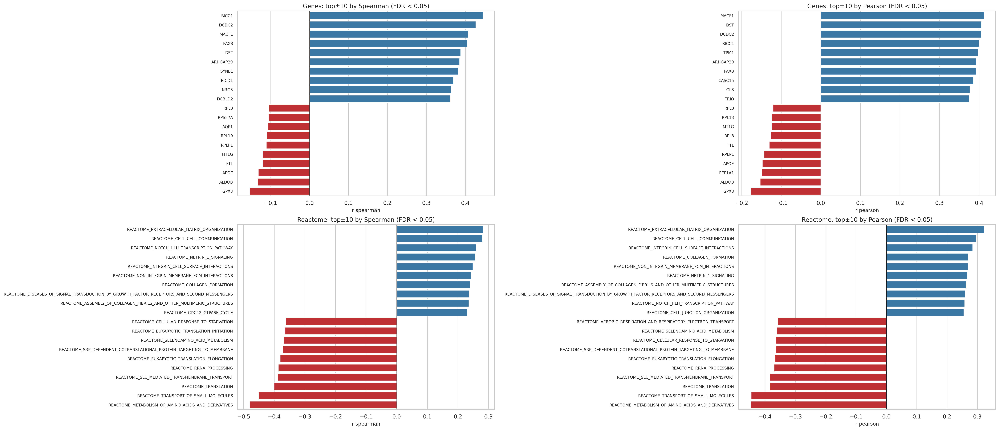

In [55]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

assert 'gene_corr' in globals(), "gene_corr not found. Run the gene correlation step first."
assert 'reactome_corr' in globals(), "reactome_corr not found. Run the reactome correlation step first."

sns.set_theme(style="whitegrid", context="notebook")

POS_COLOR = "#2C7BB6"  # blue
NEG_COLOR = "#D7191C"  # red

def build_top_df(df, r_col, padj_col, topn=10):
    """
    Keep rows with padj<0.05, pick top-N positive and top-N negative by r,
    return tidy DataFrame with columns [feature, r_col, sign], preserving order.
    """
    sub = df[[r_col, padj_col]].copy()
    sub = sub.loc[sub[padj_col].notna() & (sub[padj_col] < 0.05)]

    if sub.empty:
        return pd.DataFrame(columns=["feature", r_col, "sign"])

    pos = sub.nlargest(min(topn, len(sub)), r_col)
    neg = sub.nsmallest(min(topn, len(sub)), r_col)

    comb = pd.concat([neg, pos], axis=0)
    comb = comb[~comb.index.duplicated(keep='first')]
    comb = comb.sort_values(r_col, ascending=False)

    out = comb.reset_index()
    # Robustly rename the first column (the original index) to 'feature'
    out.rename(columns={out.columns[0]: 'feature'}, inplace=True)
    out['sign'] = np.where(out[r_col] >= 0, 'positive', 'negative')
    return out

def seaborn_bar_panel(ax, df, r_col, padj_col, title, topn=10):
    plot_df = build_top_df(df, r_col=r_col, padj_col=padj_col, topn=topn)

    if plot_df.empty:
        ax.axis('off')
        ax.text(0.5, 0.5, "No features with FDR < 0.05", ha='center', va='center', fontsize=11)
        ax.set_title(title, fontsize=12)
        return

    palette = {'positive': POS_COLOR, 'negative': NEG_COLOR}
    order = plot_df['feature'].tolist()  # explicit order to respect sorting

    sns.barplot(
        data=plot_df,
        x=r_col,
        y='feature',
        hue='sign',
        dodge=False,
        palette=palette,
        errorbar=None,
        ax=ax,
        order=order
    )
    # Optional: remove legend; comment out to keep it
    leg = ax.get_legend()
    if leg is not None:
        leg.remove()

    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel(r_col.replace('_', ' '), fontsize=10)
    ax.set_ylabel("")
    ax.set_title(title, fontsize=12)
    ax.tick_params(axis='y', labelsize=8)

fig, axes = plt.subplots(2, 2, figsize=(28, 12), constrained_layout=True)

# Genes: Spearman
seaborn_bar_panel(
    axes[0, 0],
    gene_corr,
    r_col='r_spearman',
    padj_col='padj_spearman',
    title='Genes: top±10 by Spearman (FDR < 0.05)',
    topn=10
)

# Genes: Pearson
seaborn_bar_panel(
    axes[0, 1],
    gene_corr,
    r_col='r_pearson',
    padj_col='padj_pearson',
    title='Genes: top±10 by Pearson (FDR < 0.05)',
    topn=10
)

# Reactome: Spearman
seaborn_bar_panel(
    axes[1, 0],
    reactome_corr,
    r_col='r_spearman',
    padj_col='padj_spearman',
    title='Reactome: top±10 by Spearman (FDR < 0.05)',
    topn=10
)

# Reactome: Pearson
seaborn_bar_panel(
    axes[1, 1],
    reactome_corr,
    r_col='r_pearson',
    padj_col='padj_pearson',
    title='Reactome: top±10 by Pearson (FDR < 0.05)',
    topn=10
)

plt.show()
# fig.savefig("pt_correlation_barplots_seaborn.png", dpi=300, bbox_inches='tight')

In [59]:
import pandas as pd
marker_genes = pd.read_csv("/data/ep924610/kidney_biopsy/spatial_pec_glom/DE_PECGlom_cluster12_vs_otherniches.csv")

In [60]:
marker_genes_sig = marker_genes[marker_genes["pval_adj"] < 0.05]

In [61]:
marker_genes_sig

,contrast_group,gene,score,logfoldchange,pval,pval_adj,pct_in_group,pct_out_group
0,cluster_12,CD44,18.879354,4.637423,1.686363e-79,7.892178e-77,NaN,NaN
1,cluster_12,TMSB10,16.915709,2.564646,3.446453e-64,8.064699e-62,NaN,NaN
2,cluster_12,SPECC1,15.886455,3.637595,7.865224e-57,1.226975e-54,NaN,NaN
3,cluster_12,ITGB1,15.710047,1.945126,1.290833e-55,1.510275e-53,NaN,NaN
4,cluster_12,MMP7,14.929269,3.804128,2.125830e-50,1.989777e-48,NaN,NaN
...,...,...,...,...,...,...,...,...
184,cluster_12,PRKAG2,2.352575,0.509097,1.864395e-02,3.712924e-02,NaN,NaN
185,cluster_12,STAB1,2.335019,0.659376,1.954245e-02,3.850789e-02,NaN,NaN
186,cluster_12,TIE1,2.334242,0.918810,1.958307e-02,3.850789e-02,NaN,NaN
187,cluster_12,COL18A1,2.297225,0.725639,2.160592e-02,4.230784e-02,NaN,NaN


In [62]:
marker_genes_sig_pos = marker_genes_sig[marker_genes_sig["logfoldchange"] < 0]
len(marker_genes_sig_pos)

0

In [63]:
import pandas as pd
marker_genes = pd.read_csv("/data/ep924610/kidney_biopsy/cluster_12/DE/cluster12_vs_others/markers_MAST_cluster12_vs_others.tsv", sep="	")

In [64]:
marker_genes

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
0,ITGB1,3.070070e-68,1.667544,1.000,0.892,1.436793e-65
1,CD44,2.508447e-63,3.671039,0.851,0.098,1.173953e-60
2,CFH,1.628739e-58,-2.032448,0.842,0.939,7.622499e-56
3,PDLIM7,1.403300e-45,2.448119,0.901,0.211,6.567442e-43
4,TMSB10,3.314731e-44,1.414475,1.000,0.813,1.551294e-41
...,...,...,...,...,...,...
463,HCST,4.875552e-01,-0.067998,0.030,0.017,1.000000e+00
464,SPARC,4.732013e-01,-0.048425,1.000,0.990,1.000000e+00
465,PSAP,2.003125e-02,0.032734,1.000,0.957,1.000000e+00
466,APLP2,1.088381e-01,0.030764,0.990,0.953,1.000000e+00


In [65]:
marker_genes[marker_genes["gene"]=="GRM7"]

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
23,GRM7,1.006053e-25,2.554497,0.426,0.048,4.708326e-23


In [66]:
marker_genes_sig = marker_genes[marker_genes["p_val_adj"] < 0.05]

In [67]:
marker_genes_sig.sort_values("avg_log2FC").tail(5)["gene"]

41     MEGF11
23       GRM7
9       TFPI2
189     CPNE7
1        CD44
Name: gene, dtype: object

In [68]:
bottom5 = marker_genes_sig.sort_values("avg_log2FC").head(10)["gene"].tolist()
top5 = marker_genes_sig.sort_values("avg_log2FC").tail(10)["gene"].tolist()

genes_of_interest = bottom5+ ["SLC4A11", "CFH", "CFI", "BMP7", "FGFR2"] + top5 + ["SPECC1", "ITGB1", "RUNX1", "TMSB10", "MMP7"]

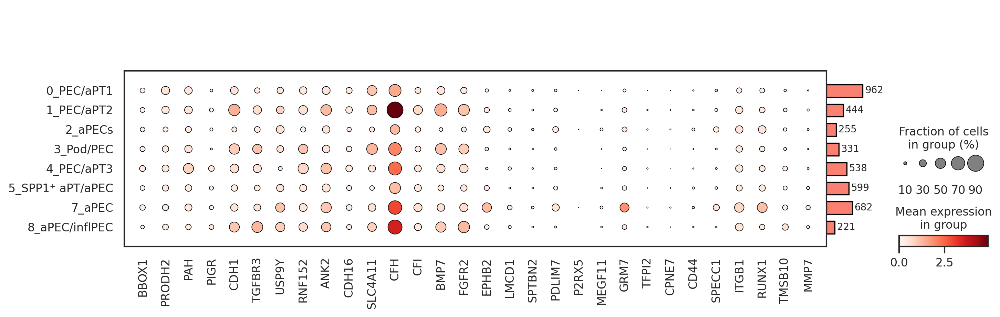

In [69]:
dp = sc.pl.dotplot(adata, genes_of_interest, 'pec_subcluster_0.80', return_fig=True)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()

In [70]:
bdata = sc.read_h5ad("/data/Kramann_lab/kidney_biopsy/results/xenium/leon/xenium_with_niches_in_glom_niche.h5ad")

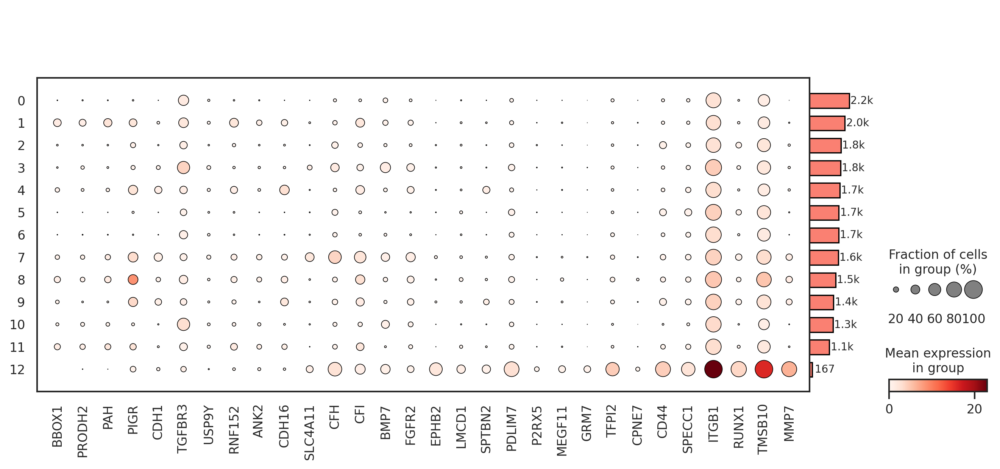

In [71]:
dp = sc.pl.dotplot(bdata, genes_of_interest, 'latent_leiden_0.6', return_fig=True)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5).show()

In [75]:
adata.write_h5ad("/data/ep924610/kidney_biopsy/trajectory_pec/pec_with_pseudotime.h5ad")

In [76]:
adata = sc.read_h5ad("/data/ep924610/kidney_biopsy/trajectory_pec/pec_with_pseudotime.h5ad")

In [77]:
adata

AnnData object with n_obs × n_vars = 4032 × 21840
    obs: 'donor_id', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'Sample', 'Group', 'date_of_biopsy_h5ad', 'ACEi', 'AT2i', 'Statin', 'corticosteroids_h5ad', 'region', 'RNAversion', 'nCounts_RNA', 'nFeatures_RNA', 'percMT_RNA', 'is_cell', 'QC1', 'pANN', 'DF', 'sclust_A', 'sclust_B', 'sclust_C', 'sclust_D', 'sclust_E', 'clust_A', 'clust_B', 'clust_C', 'clust_D', 'clust_E', 'predicted.annotation.l3.score', 'predicted.annotation.l3', 'predicted.annotation.l3.MappingScore', 'predicted.annotation.l1', 'predicted.annotation.l2', 'unfiltered_Doublets', 'leiden01', 'leiden03', 'leiden02', 'leiden04', 'subcluster_01_do_not_use', 'subcluster_02_do_not_use', 'subcluster_03_do_not_use', 'Main_Cluster_do_not_use', 'Cell_types_KPMP_do_not_use', 'Cell_types_Subclustering_do_not_use', 'Cell_types_Subclustering2_do_not_use', 'barcode_sample', 'main_class', 'subcluster', 'Study', 'library_id', 'percent.er', 'percent.mt', 'subclass.l2', 'su

In [78]:
import decoupler as dc